# IF3170 Artificial Intelligence | Tugas Besar 2

This notebook serves as a template for the assignment. Please create a copy of this notebook to complete your work. You can add more code blocks, markdown blocks, or new sections if needed.


Group Number: 31

Group Members:
- Favian Izza Diasputra (18222070)
- Henrycus Hugatama Risaldy (18223008)
- Farella Kamala Budianto (18223046)
- Kenlyn Tesalonika Winata (18223098)

## Import Libraries

In [1]:
import pandas as pd
import numpy as np
from urllib.parse import urlparse
import re
import difflib
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from scipy.stats import chi2_contingency, pointbiserialr, skew, kurtosis

# Import other libraries if needed

## Import Dataset

In [2]:
# Example of reading a csv file from a gdrive link

# Take the file id from the gdrive file url
# https://drive.google.com/file/d/1ZUtiaty9RPXhpz5F2Sy3dFPHF4YIt5iU/view?usp=sharing => The file id is 1ZUtiaty9RPXhpz5F2Sy3dFPHF4YIt5iU
# and then put it in this format:
# https://drive.google.com/uc?id={file_id}
# Don't forget to change the access to public

train = pd.read_csv("https://drive.google.com/uc?id=1BFj1nqZ0pJXraLv4W2N_Ta8tWtNT_z3o")
test = pd.read_csv("https://drive.google.com/uc?id=1yKJ_dPO7mjEDTdiskt2f45sN4aHyFsKV")
display(train.head())
display(test.head())



,ID,transaction_id,user_id,age,gender,country,device_type,device_os,merchant_category,transaction_amount,...,device_trust_score,account_age_days,has_chargeback_history,shared_ip_users,shared_device_users,merchant_risk,country_risk,distance_from_home,is_new_country,is_fraud
0,0,T0065716,15307,35,M,UK,mobile,Android,clothing,17.70,...,0.793,1056,0,1,1,0.10,0.04,9.66,0,1
1,1,T0027857,1226,54,F,IN,mobile,Android,restaurants,NaN,...,NaN,1867,0,1,1,0.12,0.10,12.05,0,1
2,2,T0055953,16072,35,M,US,desktop,iOS,restaurants,5.20,...,0.281,1726,1,2,2,0.12,0.05,181.28,0,0
3,3,T0083660,725,23,F,US,mobile,Android,electronics,180.70,...,0.061,30,1,1,1,0.30,0.05,33.26,0,0
4,4,T0017674,7367,32,M,UK,mobile,Android,gas,35.45,...,0.592,1386,0,3,1,0.05,0.04,174.83,0,0


,ID,transaction_id,user_id,age,gender,country,device_type,device_os,merchant_category,transaction_amount,...,ip_risk_score,device_trust_score,account_age_days,has_chargeback_history,shared_ip_users,shared_device_users,merchant_risk,country_risk,distance_from_home,is_new_country
0,0,T0065716,1199,58,M,UK,tablet,Android,gas,3.54,...,0.906,0.595,2305,0,3,3,0.05,0.04,13.55,0
1,1,T0027857,29841,71,M,BR,desktop,Android,groceries,94.80,...,0.917,0.553,2911,0,3,3,0.05,0.13,6.09,0
2,2,T0055953,25403,76,F,CA,tablet,iOS,restaurants,84.45,...,0.675,0.614,2952,0,1,1,0.12,0.03,118.59,0
3,3,T0083660,27600,70,F,UK,mobile,iOS,gas,23.66,...,0.541,0.493,2539,0,2,2,0.05,0.04,255.86,0
4,4,T0017674,21543,70,F,US,mobile,Windows,travel,81.45,...,0.832,0.183,1017,0,1,2,0.35,0.05,16.19,0


# Exploratory Data Analysis (Optional)

Exploratory Data Analysis (EDA) is a crucial step in the data analysis process that involves examining and visualizing data sets to uncover patterns, trends, anomalies, and insights. It is the first step before applying more advanced statistical and machine learning techniques. EDA helps you to gain a deep understanding of the data you are working with, allowing you to make informed decisions and formulate hypotheses for further analysis.

In [3]:
# import seaborn as sns
# import matplotlib.pyplot as plt

# sns.set(style="whitegrid")

# print("=== SHAPE DATA ===")
# print("Train:", train.shape)
# print("Test :", test.shape)
# print()

# print("=== FIRST 5 ROWS ===")
# print(df_eda.head(), "\n")

# print("=== INFO DATA ===")
# print(df_eda.info(), "\n")

# print("=== DESCRIPTIVE STATISTICS ===")
# print(df_eda.describe(), "\n")

# print("=== MISSING VALUES ===")
# print(df_eda.isnull().sum(), "\n")

# # ==============================
# # DISTRIBUSI LABEL
# # ==============================
# plt.figure(figsize=(4, 3))
# sns.countplot(data=df_eda, x="is_fraud", color="orange")
# plt.title("Label Distribution (is_fraud)")
# plt.xlabel("is_fraud (0 = Non-Fraud, 1 = Fraud)")
# plt.ylabel("Count")
# plt.show()

# print("=== DISTRIBUTION PROPORTION ===")
# print(df_eda["is_fraud"].value_counts(normalize=True).rename("proportion"))
# print()

# # ==============================
# # DISTRIBUSI TRANSACTION AMOUNT
# # ==============================
# plt.figure(figsize=(6, 4))
# sns.histplot(df_eda["transaction_amount"], bins=30, kde=True)
# plt.title("Distribution of Transaction Amount")
# plt.xlabel("Transaction Amount")
# plt.ylabel("Frequency")
# plt.show()

# # ==============================
# # BOX PLOT
# # ==============================
# plt.figure(figsize=(6, 4))
# sns.boxplot(data=df_eda, x="is_fraud", y="transaction_amount")
# plt.title("Transaction Amount vs Fraud")
# plt.xlabel("is_fraud (0 = Non-Fraud, 1 = Fraud)")
# plt.ylabel("Transaction Amount")
# plt.show()

# # ==============================
# # HEATMAP CORRELATION
# # ==============================
# numeric_cols = df_eda.select_dtypes(include=['int64', 'float64'])

# plt.figure(figsize=(12, 6))
# sns.heatmap(numeric_cols.corr(), cmap="coolwarm", annot=False)
# plt.title("Correlation Heatmap")
# plt.show()

# print("=== EDA Selesai ===")


## A. Data Understanding
The objective of this section is for participants to understand the quality of the provided data. This includes:

1. Data Size
2. Statistics of Each Feature
3. Outliers
4. Correlation
5. Distribution

### Step 1

Find the following:

1. The size of the data (instances and features).
2. Categorization of features
3. The data type and number of unique values.
4. The minimum, maximum, mean, median, and standard deviation values for non-categorical features.
5. Explain the significance of gathering the first four pieces of information.

#### 1. The size of the data (instances and features)

In [4]:
print(f"Size of the data: {train.shape} \n")

Size of the data: (100000, 31) 



#### 2. Categorization of features

In [5]:
def classify_features(df, id_cols=['ID', 'transaction_id', 'user_id'], target_col='is_fraud'):
    # 1. Inisialisasi List
    cols_drop = id_cols.copy()
    cols_binary = []
    cols_nominal = []
    cols_numerical = []

    # 2. Iterasi setiap kolom
    for col in df.columns:
        if col in id_cols or col == target_col:
            continue

        n_unique = df[col].nunique()
        dtype = df[col].dtype

        # --- Rule 2: Binary ---
        if n_unique == 2:
            cols_binary.append(col)

        # --- Rule 3: Object / Low Card Int (Nominal) ---
        elif dtype == 'object' or (str(dtype).startswith('int') and n_unique <= 10 and 'risk' not in col and 'users' not in col and 'attempts' not in col):
            # Note: Kita exclude 'risk', 'users', 'attempts' agar tetap masuk numerik
            cols_nominal.append(col)

        # --- Rule 4: Numerical (Sisanya) ---
        else:
            cols_numerical.append(col)

    return cols_drop, cols_binary, cols_nominal, cols_numerical

# Eksekusi
drop_list, bin_list, nom_list, num_list = classify_features(train)

print(f"Drop/IDs: {len(drop_list)} -> {drop_list}")
print(f"Binary:   {len(bin_list)} -> {bin_list}")
print(f"Nominal:  {len(nom_list)} -> {nom_list}")
print(f"Numerical:{len(num_list)} -> {num_list}")

Drop/IDs: 3 -> ['ID', 'transaction_id', 'user_id']
Binary:   3 -> ['gender', 'has_chargeback_history', 'is_new_country']
Nominal:  6 -> ['country', 'device_type', 'device_os', 'merchant_category', 'transaction_type', 'day_of_week']
Numerical:18 -> ['age', 'transaction_amount', 'time_of_day', 'transaction_duration', 'num_prev_transactions', 'avg_transaction_amount', 'std_transaction_amount', 'transactions_last_24h', 'transactions_last_1h', 'failed_login_attempts', 'ip_risk_score', 'device_trust_score', 'account_age_days', 'shared_ip_users', 'shared_device_users', 'merchant_risk', 'country_risk', 'distance_from_home']


#### 3. The data type and number of unique values.

In [6]:
cols_with_unique_list = bin_list + nom_list
cols_only_count = num_list

print("--- Kolom Kategorikal (Binary dan Nominal) ---")
df_cat = pd.DataFrame({
    'Column': cols_with_unique_list,
    'Dtype': [train[col].dtype for col in cols_with_unique_list],
    'Unique Count': [train[col].nunique() for col in cols_with_unique_list],
    'Unique Values List': [train[col].unique().tolist() for col in cols_with_unique_list]
})

display(df_cat.style.set_properties(**{'text-align': 'left'})
        .set_table_styles([{'selector': 'th', 'props': [('text-align', 'center')]}])
        .hide(axis="index"))

print("\n--- Kolom Numerik (Kontinu) ---")
df_num = pd.DataFrame({
    'Column': cols_only_count,
    'Dtype': [train[col].dtype for col in cols_only_count],
    'Unique Count': [train[col].nunique() for col in cols_only_count]
})

display(df_num.style.set_properties(**{'text-align': 'center'})
        .set_table_styles([{'selector': 'th', 'props': [('text-align', 'center')]}])
        .hide(axis="index"))

--- Kolom Kategorikal (Binary dan Nominal) ---


Column,Dtype,Unique Count,Unique Values List
gender,object,2,"['M', 'F']"
has_chargeback_history,int64,2,"[0, 1]"
is_new_country,int64,2,"[0, 1]"
country,object,10,"['UK', 'IN', 'US', 'ID', 'BR', 'CA', 'DE', 'AU', 'FR', 'SG']"
device_type,object,3,"['mobile', 'desktop', 'tablet']"
device_os,object,5,"['Android', 'iOS', 'Windows', 'Linux', 'MacOS']"
merchant_category,object,9,"['clothing', 'restaurants', 'electronics', 'gas', 'services', 'groceries', 'travel', 'financial', 'luxury']"
transaction_type,object,4,"['purchase', 'topup', 'withdrawal', 'transfer']"
day_of_week,int64,7,"[1, 3, 5, 0, 4, 6, 2]"



--- Kolom Numerik (Kontinu) ---


Column,Dtype,Unique Count
age,int64,62
transaction_amount,float64,28920
time_of_day,int64,24
transaction_duration,float64,2448
num_prev_transactions,int64,49
avg_transaction_amount,float64,14709
std_transaction_amount,float64,7501
transactions_last_24h,int64,45
transactions_last_1h,int64,16
failed_login_attempts,int64,6


#### 4. The minimum, maximum, mean, median, and standard deviation values for numerical features.

In [7]:
descriptive_stats = train[num_list].describe().T[['min', 'max', 'mean', '50%', 'std']].rename(
    columns={'50%': 'Median', 'min': 'Min', 'max': 'Max', 'mean': 'Mean', 'std': 'Std'}
).round(1).reset_index().rename(columns={'index': 'Column'})

# Urutkan kolom sesuai permintaan
descriptive_stats = descriptive_stats[['Column', 'Min', 'Max', 'Mean', 'Median', 'Std']]
display(descriptive_stats.style.format("{:.1f}", subset=['Min', 'Max', 'Mean', 'Median', 'Std'])
        .set_properties(**{'text-align': 'center'})
        .set_table_styles([{'selector': 'th', 'props': [('text-align', 'center')]}])
        .hide(axis="index"))

Column,Min,Max,Mean,Median,Std
age,18.0,79.0,48.5,48.0,17.9
transaction_amount,0.0,20601.1,126.9,64.5,376.0
time_of_day,0.0,23.0,12.8,12.0,5.7
transaction_duration,0.0,52.1,4.0,2.8,4.0
num_prev_transactions,8.0,59.0,30.0,30.0,5.5
avg_transaction_amount,-52.9,195.8,70.0,70.0,30.0
std_transaction_amount,5.0,80.0,42.5,42.5,21.7
transactions_last_24h,0.0,44.0,2.0,1.0,4.0
transactions_last_1h,0.0,15.0,0.3,0.0,1.5
failed_login_attempts,0.0,5.0,0.3,0.0,0.5


#### 5. Correlation between categorical and label

--- Menganalisis 9 Kolom Kategorikal ---

=== Crosstab: gender vs is_fraud ===
gender        F      M
is_fraud              
0         35336  50536
1          5801   8327
------------------------------


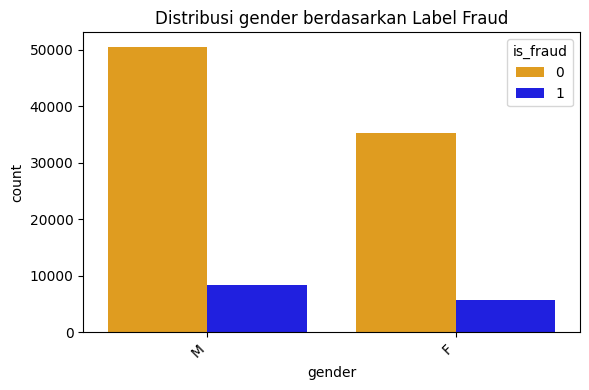


=== Crosstab: has_chargeback_history vs is_fraud ===
has_chargeback_history      0     1
is_fraud                           
0                       81263  4609
1                       12710  1418
------------------------------


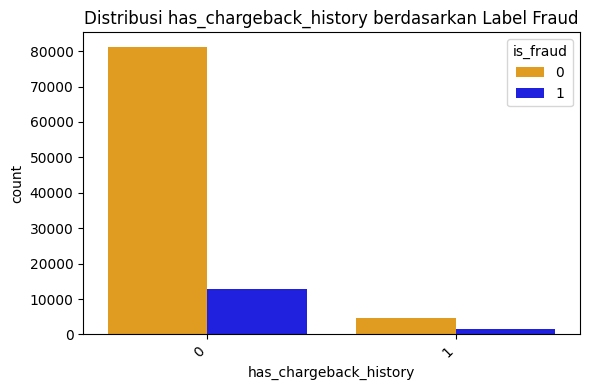


=== Crosstab: is_new_country vs is_fraud ===
is_new_country      0     1
is_fraud                   
0               81910  3962
1               13132   996
------------------------------


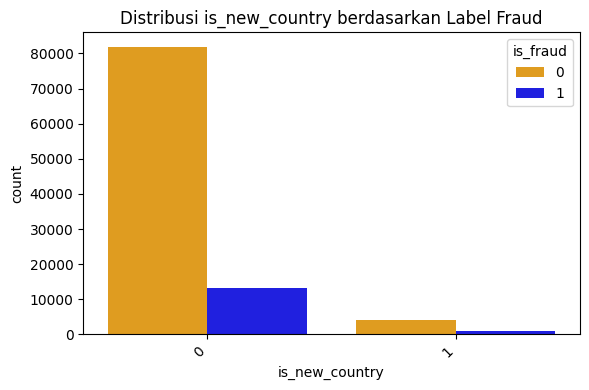


=== Crosstab: country vs is_fraud ===
country    AU    BR    CA    DE    FR     ID     IN   SG    UK     US
is_fraud                                                             
0         400  2214  9652  1253  1534  10370  25229  438  9260  25522
1          50   387  1569   209   232   1694   4146   57  1575   4209
------------------------------


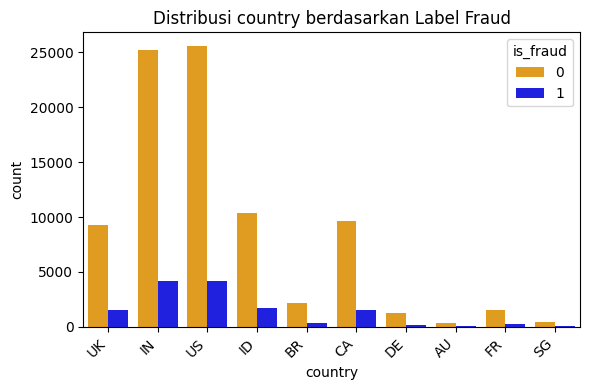


=== Crosstab: device_type vs is_fraud ===
device_type  desktop  mobile  tablet
is_fraud                            
0              16201   66501    3170
1               1962   11791     375
------------------------------


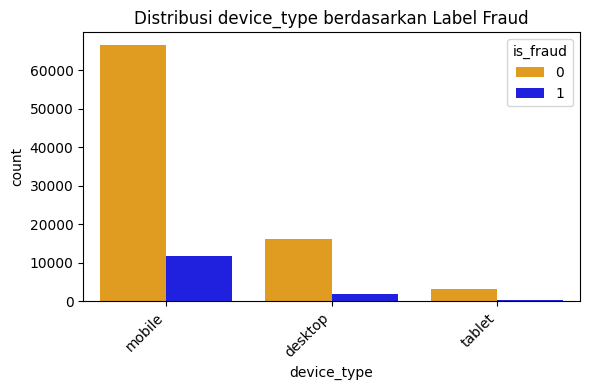


=== Crosstab: device_os vs is_fraud ===
device_os  Android  Linux  MacOS  Windows    iOS
is_fraud                                        
0            42247   5431   1513    17802  18879
1             6936    883    250     2948   3111
------------------------------


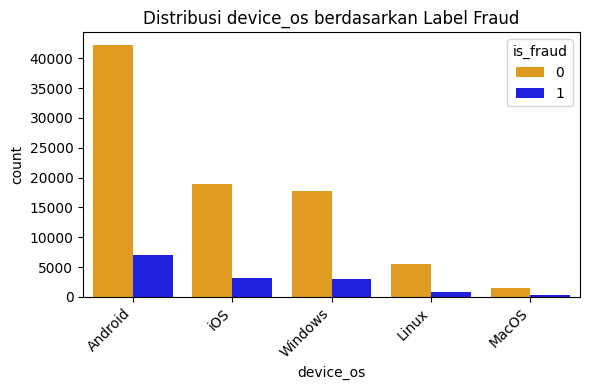


=== Crosstab: merchant_category vs is_fraud ===
merchant_category  clothing  electronics  financial    gas  groceries  luxury  \
is_fraud                                                                        
0                      4430        23938       3690  11409       8361     929   
1                       749         4035        714   1751       1301     180   

merchant_category  restaurants  services  travel  
is_fraud                                          
0                        21666      4046    7403  
1                         3489       616    1293  
------------------------------


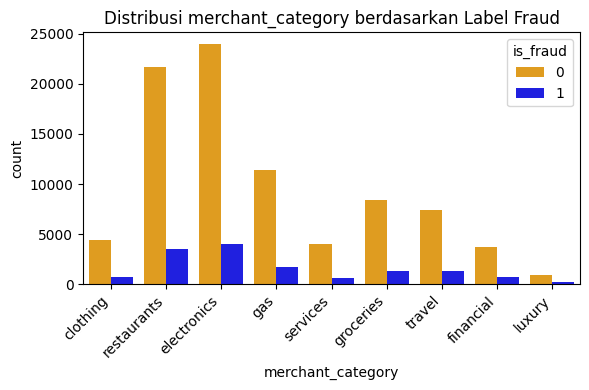


=== Crosstab: transaction_type vs is_fraud ===
transaction_type  purchase  topup  transfer  withdrawal
is_fraud                                               
0                    50871  12173      8543       14285
1                     8524   2005      1333        2266
------------------------------


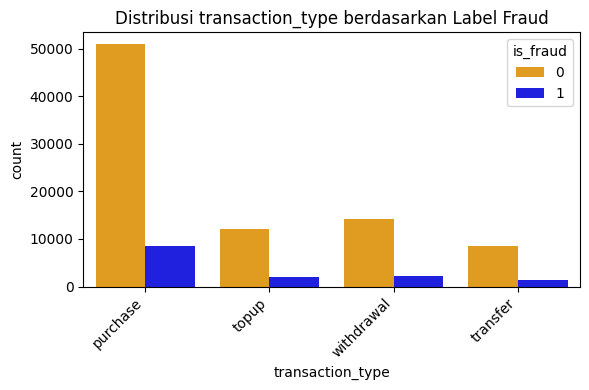


=== Crosstab: day_of_week vs is_fraud ===
day_of_week      0      1     2      3      4      5     6
is_fraud                                                  
0            16182  16038  6541  11057  13333  12831  9890
1             2728   2659  1054   1832   2198   2045  1612
------------------------------


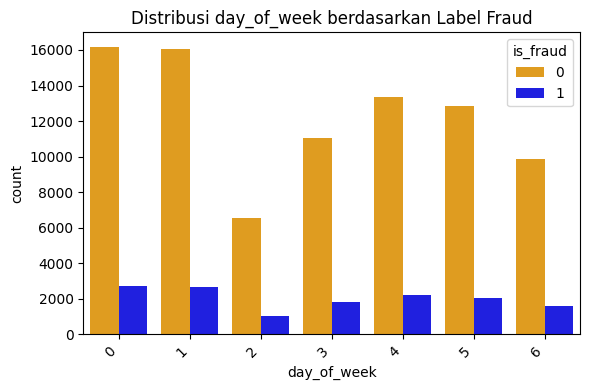

In [8]:
df_cat = train.copy()
label_col = "is_fraud"

categorical_columns = bin_list + nom_list

# --------------------------------------------
# Fungsi Ringkas untuk Analisis dan Plot
# --------------------------------------------

def analyze_and_plot_categorical(df, cols, label_col):
    """Menghitung crosstab, mencetak contoh, dan membuat plot untuk setiap kolom."""

    print(f"--- Menganalisis {len(cols)} Kolom Kategorikal ---")

    for col in cols:
        if col == label_col:
            continue

        if col not in df.columns:
            print(f"[WARNING] Kolom '{col}' tidak ada, skip.")
            continue

        # 1. Hitung Crosstab (Kategori vs Label)
        pair_counts = df.groupby([label_col, col]).size().unstack(fill_value=0)

        # Cetak Hasil Crosstab
        print(f"\n=== Crosstab: {col} vs {label_col} ===")
        print(pair_counts)
        print("-" * 30)

        # 2. Plot Distribusi
        plt.figure(figsize=(6, 4))
        sns.countplot(
            data=df,
            x=col,
            hue=label_col,
            palette={0: "orange", 1: "blue"}
        )
        plt.title(f"Distribusi {col} berdasarkan Label Fraud")
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()

# --------------------------------------------
# Eksekusi Analisis
# --------------------------------------------
analyze_and_plot_categorical(df_cat, categorical_columns, label_col)

In [9]:
analyze_cols = bin_list + nom_list
print("--- Value Counts untuk Kolom Biner dan Nominal ---")

for col in analyze_cols:
    if col in train.columns:
        print(f"\n==================== {col} ====================")
        # Gunakan value_counts() untuk menghitung setiap nilai unik
        print(train[col].value_counts(dropna=False)) # dropna=False untuk menyertakan nilai NaN
    else:
        print(f"[WARNING] Kolom '{col}' tidak ditemukan di DataFrame train.")

# Tambahan: Hanya print nunique untuk kolom Numerik Kontinu (num_list)
print("\n--- Jumlah Unique Values (n-unique) untuk Kolom Numerik Kontinu ---")
for col in num_list:
    if col in train.columns:
        print(f"{col}: {train[col].nunique()}")

--- Value Counts untuk Kolom Biner dan Nominal ---

==================== gender ====================
gender
M    58863
F    41137
Name: count, dtype: int64

==================== has_chargeback_history ====================
has_chargeback_history
0    93973
1     6027
Name: count, dtype: int64

==================== is_new_country ====================
is_new_country
0    95042
1     4958
Name: count, dtype: int64

==================== country ====================
country
US    29731
IN    29375
ID    12064
CA    11221
UK    10835
BR     2601
FR     1766
DE     1462
SG      495
AU      450
Name: count, dtype: int64

==================== device_type ====================
device_type
mobile     78292
desktop    18163
tablet      3545
Name: count, dtype: int64

==================== device_os ====================
device_os
Android    49183
iOS        21990
Windows    20750
Linux       6314
MacOS       1763
Name: count, dtype: int64

==================== merchant_category ====================
me

#### 5. Explain the significance of gathering the first four pieces of information.


Tujuan dari mengumpulkan informasi tentang ukuran data (instansi
dan fitur) adalah untuk memahami sejauh mana data yang tersedia
dapat mewakili masalah yang ingin diselesaikan. Selain itu, mengetahui tipe data dari setiap fitur yang ada dapat membantu dalam memilih teknik analisis yang tepat. Jumlah nilai unik untuk fitur kategorikal memberikan wawasan tentang variabilitas data, sedangkan nilai minimum, maksimum, rata-rata, median, dan standar deviasi untuk fitur non-kategorikal memungkinkan untuk menilai distribusi data dan mendeteksi potensi outlier atau masalah kualitas lainnya.

### Step 2

Find the following:

1. Missing values for each feature.
2. Outliers for each feature (use the methods you are familiar with).
3. Why is it necessary to identify missing values and outliers?

#### 1. Missing values for each feature.

In [10]:
def missing_value(df):
    df = df.drop(columns=['id'], errors='ignore')
    sum_df = pd.concat([df.isna().sum().rename('Number_of_missing_values')], axis=1).fillna('-')
    sum_df = sum_df.reset_index().rename(columns={'index': 'Column'})

    # Displaying with custom styling
    return sum_df.style.set_properties(**{'text-align': 'center'}) \
                        .set_table_styles([{'selector': 'th', 'props': [('text-align', 'center')]}]) \
                        .hide(axis="index")

display(missing_value(train))

Column,Number_of_missing_values
ID,0
transaction_id,0
user_id,0
age,0
gender,0
country,0
device_type,0
device_os,0
merchant_category,0
transaction_amount,2419


#### 2. Outliers for each feature (use the methods you are familiar with).

In [11]:
outlier_info = {}

for col in num_list:
    series = train[col]

    # 1. Hitung Batasan IQR
    Q1, Q3 = series.quantile(0.25), series.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound, upper_bound = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR

    # 2. Deteksi Outlier
    mask_outlier = (series < lower_bound) | (series > upper_bound)
    outliers = series[mask_outlier]

    if not outliers.empty:
        # Kumpulkan informasi detail outlier
        outlier_info[col] = {
            'Jumlah Outlier': len(outliers),
            'Lower Bound': lower_bound,
            'Upper Bound': upper_bound,
            'Min Outlier': outliers.min(),
            'Max Outlier': outliers.max(),
            'Contoh Nilai Outlier (Unique)': sorted(outliers.unique().tolist())[:10],
            '5 Smallest Outliers': outliers.nsmallest(5).tolist(),
            '5 Largest Outliers': outliers.nlargest(5).tolist(),
        }

# 3. Buat DataFrame Ringkasan
outlier_df = pd.DataFrame.from_dict(outlier_info, orient='index').reset_index().rename(columns={'index': 'Column'})

# 4. Hitung Persentase Outlier
outlier_df['Persentase Outlier (%)'] = (outlier_df['Jumlah Outlier'] / len(train) * 100)

# 5. Tentukan format untuk kolom numerik (2 desimal)
float_cols = ['Lower Bound', 'Upper Bound', 'Min Outlier', 'Max Outlier', 'Persentase Outlier (%)']
style_format = {col: '{:.2f}' for col in float_cols}

# 6. Tampilkan dengan formatting
display(
    outlier_df.style
    .format(style_format, na_rep='-')
    .set_properties(**{'text-align': 'center'})
    .set_table_styles([{'selector': 'th', 'props': [('text-align', 'center')]}])
    .hide(axis="index")
)

Column,Jumlah Outlier,Lower Bound,Upper Bound,Min Outlier,Max Outlier,Contoh Nilai Outlier (Unique),5 Smallest Outliers,5 Largest Outliers,Persentase Outlier (%)
transaction_amount,5904,-129.32,287.29,287.31,20601.13,"[287.31, 287.36, 287.37, 287.41, 287.42, 287.51, 287.52, 287.54, 287.59, 287.6]","[287.31, 287.36, 287.37, 287.41, 287.41]","[20601.133349564803, 13482.877273785814, 11996.508187767236, 11670.285313267352, 11119.033727072972]",5.90
transaction_duration,4903,-5.44,12.12,12.13,52.07,"[12.13, 12.14, 12.15, 12.16, 12.17, 12.18, 12.19, 12.2, 12.21, 12.22]","[12.13, 12.13, 12.13, 12.13, 12.13]","[52.07, 46.1, 45.49, 45.46, 42.86]",4.90
num_prev_transactions,264,14.00,46.00,8.00,59.00,"[8, 10, 11, 12, 13, 47, 48, 49, 50, 51]","[8, 10, 10, 10, 10]","[59, 56, 55, 54, 54]",0.26
avg_transaction_amount,655,-10.92,150.95,-52.89,195.79,"[-52.89, -51.03, -46.47, -45.48, -45.07, -42.02, -41.77, -41.36, -41.08, -40.82]","[-52.89, -51.03, -46.47, -45.48, -45.07]","[195.79, 190.42, 189.46, 187.85, 185.04]",0.66
transactions_last_24h,8878,-0.50,3.50,4.00,44.00,"[4, 5, 6, 7, 8, 9, 10, 11, 12, 13]","[4, 4, 4, 4, 4]","[44, 43, 43, 42, 42]",8.88
transactions_last_1h,11697,0.00,0.00,1.00,15.00,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]","[1, 1, 1, 1, 1]","[15, 15, 15, 15, 15]",11.70
failed_login_attempts,363,-1.50,2.50,3.00,5.00,"[3, 4, 5]","[3, 3, 3, 3, 3]","[5, 5, 5, 4, 4]",0.36
shared_ip_users,470,-2.00,6.00,7.00,11.00,"[7, 8, 9, 10, 11]","[7, 7, 7, 7, 7]","[11, 10, 10, 10, 10]",0.47
shared_device_users,6612,-0.50,3.50,4.00,11.00,"[4, 5, 6, 7, 8, 9, 11]","[4, 4, 4, 4, 4]","[11, 9, 8, 8, 8]",6.61
distance_from_home,5550,-142.61,316.67,316.76,6388.52,"[316.76, 316.8, 316.82, 316.84, 316.9, 316.91, 316.92, 316.93, 316.96, 316.97]","[316.76, 316.8, 316.8, 316.82, 316.84]","[6388.517628034585, 6268.764363076312, 6140.219187623593, 6020.868786468015, 5917.408250064255]",5.55


#### 3. Why is it necessary to identify missing values and outliers?

Identifikasi missing values dan outliers merupakan hal yang wajib dilakukan untuk analisis data sebelum dilakukan pemodelan karena beberapa alasan sebagai berikut.
- Missing value dapat mempengaruhi **kualitas data** yang menyebabkan hasil menjadi bias. Selain itu, missing value juga dapat **merusak integritas data** sehingga sulit untuk menarik insight dari data.
- Outlier dapat dapat **mempengaruhi estimasi statistik** karena distribusi data yang terlalu berbeda sehingga sulit untuk mengidentifikasi pola yang dapat mengarah pada **kesimpulan yang salah**.

Kedua hal ini dapat **menurunkan kualitas data** dan **mempengaruhi akurasi prediksi model** sehingga perlu ditangani dengan tepat sebelum analisis lebih lanjut dilakukan.

### Step 3

Find the following:

1. Correlations between features.
2. Visualize the distribution of each feature (categorical and continuous).
3. Visualize the correlation between features and the target variable.
4. Explain the significance of understanding feature distributions and correlations.

#### 1. Correlations between features.

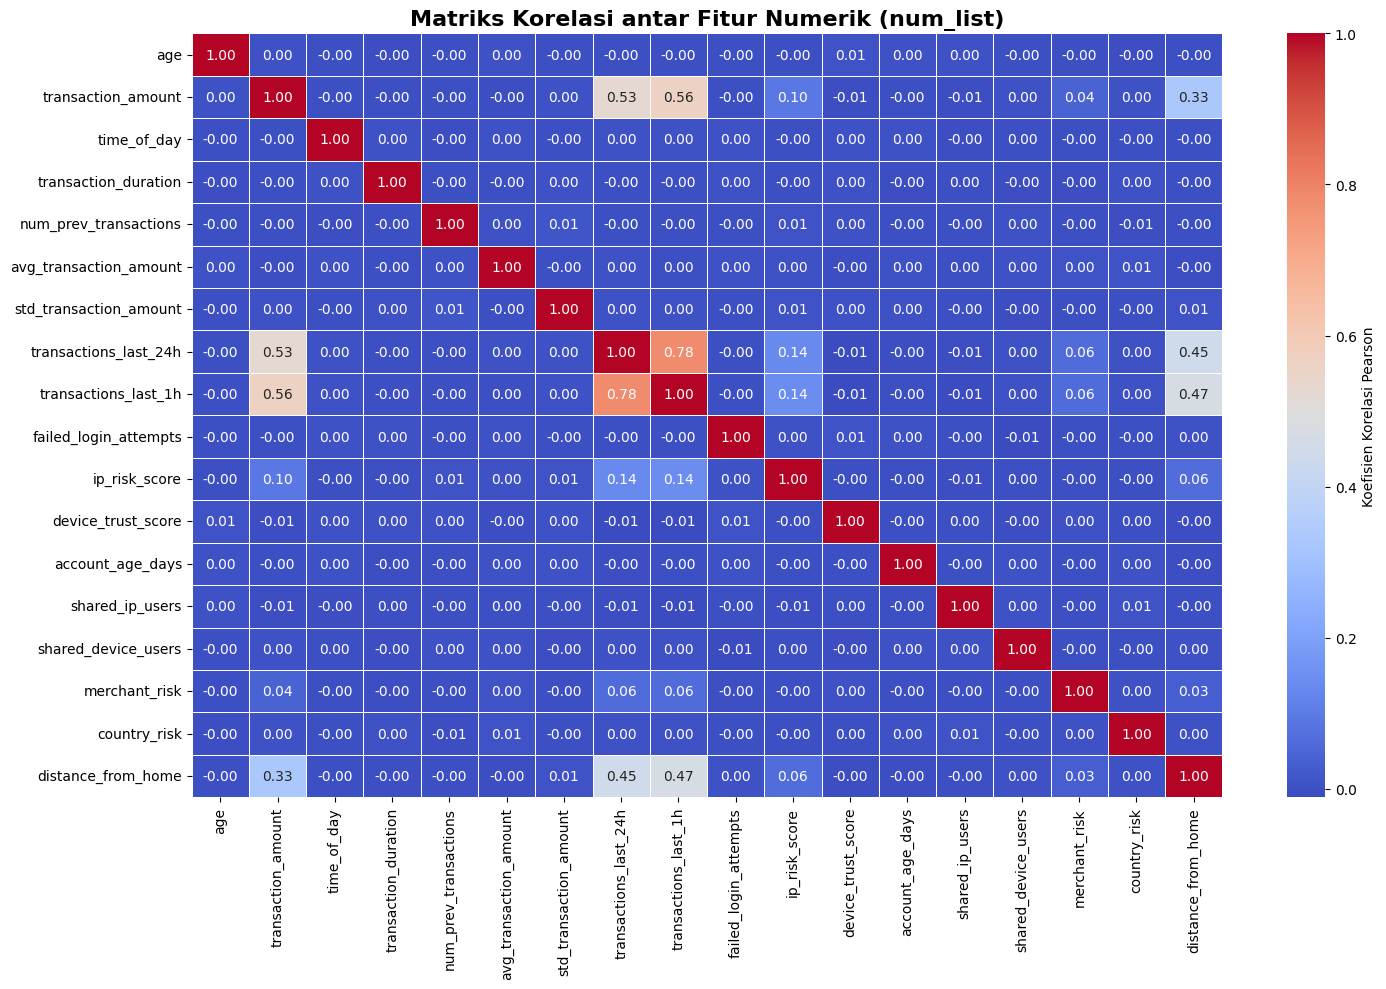

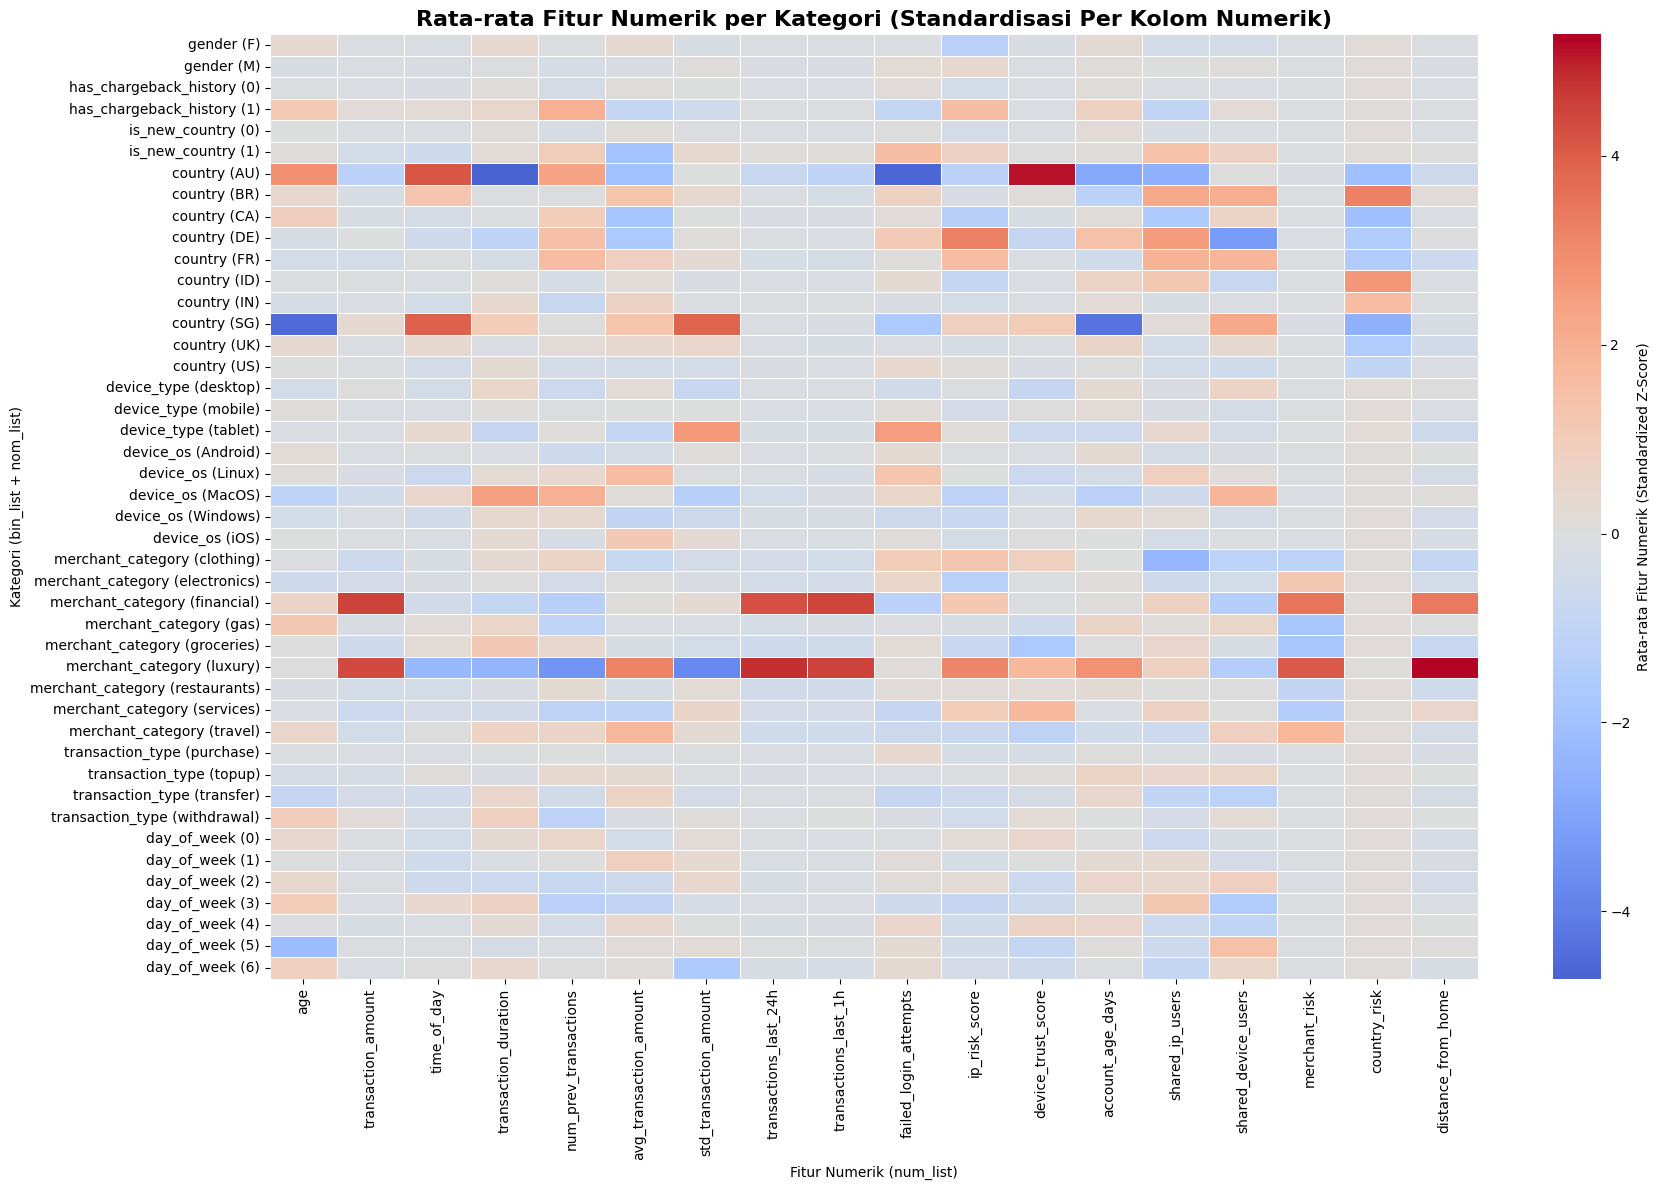


--- Ringkasan Perbandingan Kategori (Mean, Data Mentah) ---


,age,transaction_amount,time_of_day,transaction_duration,num_prev_transactions,avg_transaction_amount,std_transaction_amount,transactions_last_24h,transactions_last_1h,failed_login_attempts,ip_risk_score,device_trust_score,account_age_days,shared_ip_users,shared_device_users,merchant_risk,country_risk,distance_from_home
gender (F),48.584802,128.345650,12.773051,4.015276,30.001702,70.068150,42.475048,2.062110,0.318618,0.296497,0.496952,0.499216,1498.933879,1.996597,1.495953,0.193362,0.071377,118.061501
gender (M),48.413808,125.817427,12.768140,3.988622,29.985356,69.901179,42.587446,2.024803,0.302669,0.299237,0.502800,0.499664,1496.201536,2.003687,1.502489,0.192713,0.071287,116.957383
has_chargeback_history (0),48.464974,126.389063,12.766795,3.998121,29.982676,69.988815,42.551537,2.036947,0.308333,0.298660,0.499995,0.499487,1496.708927,2.001649,1.499505,0.192872,0.071332,117.351189
has_chargeback_history (1),48.783143,134.114439,12.822631,4.022449,30.138709,69.672444,42.380168,2.090095,0.323212,0.289530,0.506629,0.499385,1506.939771,1.987058,1.504397,0.194662,0.071203,118.353261
is_new_country (0),48.483481,127.222725,12.772764,3.999354,29.988111,70.002315,42.533567,2.035469,0.307443,0.297458,0.500213,0.499431,1497.413901,1.999358,1.499148,0.192842,0.071338,117.291506


In [12]:
# ============================================
# KORELASI NUMERIK-NUMERIK (Heatmap Standar)
# ============================================

def numeric_correlations_simplified(df, num_list):
    """Menghitung dan memvisualisasikan matriks korelasi Pearson antar fitur numerik kontinu."""

    if not num_list:
        print("Daftar kolom numerik kontinu (num_list) kosong. Skip korelasi numerik.")
        return

    # Hitung Matriks Korelasi Pearson
    corr_matrix = df[num_list].corr()

    # Visualisasi
    plt.figure(figsize=(15, 10))
    sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5,
                cbar_kws={'label': 'Koefisien Korelasi Pearson'})
    plt.title('Matriks Korelasi antar Fitur Numerik (num_list)', fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()

# ============================================
# KORELASI KATEGORIKAL-NUMERIK (Perbandingan Mean - Dinormalisasi per Kolom)
# ============================================

def categorical_numeric_comparison_simplified(df, cat_list, num_list):
    """
    Menghitung mean fitur numerik per kategori, kemudian menormalisasi hasilnya
    PER KOLOM NUMERIK sebelum membuat heatmap.
    """
    if not cat_list or not num_list:
        print("Daftar kolom kategorikal atau numerik kosong. Skip perbandingan.")
        return None

    all_cat_cols = cat_list
    heatmap_data = {}

    # 1. Hitung Mean Per Kategori (Data Mentah)
    for cat_col in all_cat_cols:
        grouped_mean = df.groupby(cat_col)[num_list].mean()
        for cat_val in grouped_mean.index:
            col_name = f"{cat_col} ({cat_val})"
            heatmap_data[col_name] = grouped_mean.loc[cat_val]

    comparison_df = pd.DataFrame(heatmap_data).T # Baris: Kategori, Kolom: Numerik

    # 2. Normalisasi Z-Score PER KOLOM NUMERIK
    # Ini memastikan setiap kolom numerik memiliki skala warnanya sendiri
    scaler = StandardScaler()
    # Terapkan normalisasi pada kolom (axis=0)
    # Hasilnya akan menjadi array numpy, konversi kembali ke DataFrame dengan nama kolom yang sama
    normalized_data = scaler.fit_transform(comparison_df[num_list].fillna(0))
    comparison_normalized_df = pd.DataFrame(normalized_data,
                                            index=comparison_df.index,
                                            columns=comparison_df.columns)

    # Visualisasi Heatmap (Data yang sudah Dinormalisasi)
    plt.figure(figsize=(18, 12))
    sns.heatmap(comparison_normalized_df,
                annot=False, # Matriks sudah dinormalisasi, nilai mentah tidak informatif
                cmap='coolwarm',
                fmt='.2f',
                linewidths=0.5,
                center=0, # Pusat skala warna di 0 (mean setelah standardisasi)
                cbar_kws={'label': 'Rata-rata Fitur Numerik (Standardized Z-Score)'})

    plt.title('Rata-rata Fitur Numerik per Kategori (Standardisasi Per Kolom Numerik)', fontsize=16, fontweight='bold')
    plt.xlabel('Fitur Numerik (num_list)')
    plt.ylabel('Kategori (bin_list + nom_list)')
    plt.tight_layout()
    plt.show()

    return comparison_df # Kembalikan data mentah (un-normalized)

# --------------------------------------------
# EKSEKUSI
# --------------------------------------------
# Korelasi Numerik-Numerik
numeric_correlations_simplified(train, num_list)
print("\n" + "="*50)

# Korelasi Kategorikal-Numerik
all_categorical_cols = bin_list + nom_list
correlation_df_comparison = categorical_numeric_comparison_simplified(train, all_categorical_cols, num_list)

# Tampilkan data korelasi yang dihasilkan (jika ada)
if correlation_df_comparison is not None:
    print("\n--- Ringkasan Perbandingan Kategori (Mean, Data Mentah) ---")
    display(correlation_df_comparison.head())

#### 2. Visualize the distribution of each feature (categorical and continuous).

## age


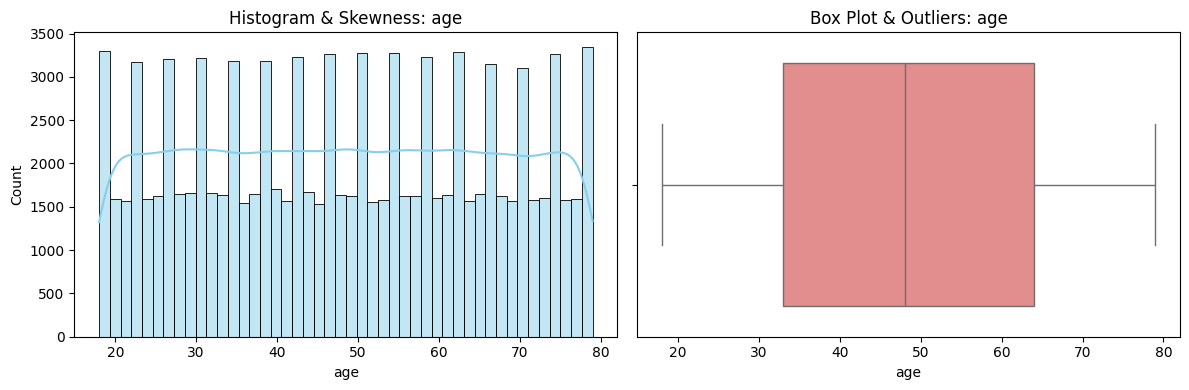

### 📊 Statistik Kuantitatif

,Value
Count (Valid),100000.000000
Mean,48.4841
Median,48.0000
Std Dev,17.8922
Min,18.0000
Max,79.0000
Skewness,0.0029
Kurtosis,-1.1958


### 🧠 Analisis & Insight

- Skewness berada dalam rentang normal (0.00). Distribusi relatif simetris di sekitar Mean/Median.
- Kurtosis (-1.20) negatif (**Platykurtik**), menunjukkan ekor yang 'ringan' dan distribusi yang lebih datar (variasi yang lebih tersebar) daripada distribusi normal.
- Tidak terdeteksi adanya *outlier* signifikan berdasarkan aturan 1.5x IQR.

## transaction_amount


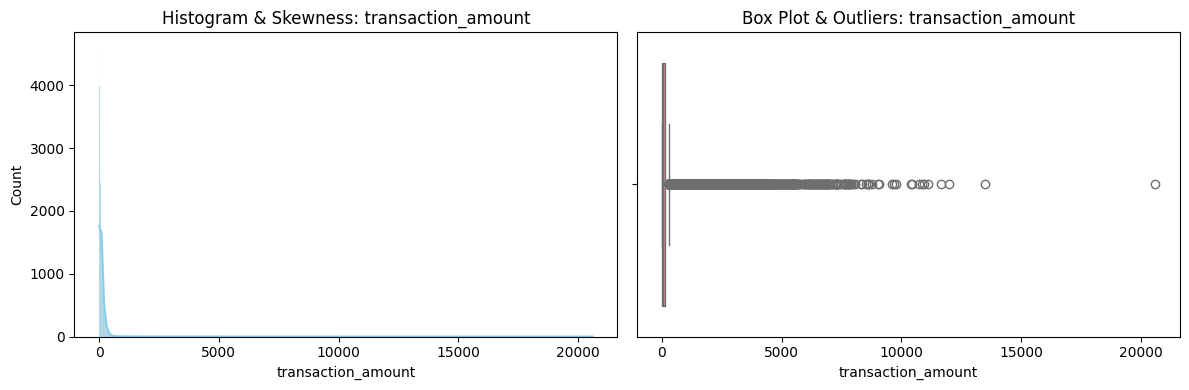

### 📊 Statistik Kuantitatif

,Value
Count (Valid),97581.000000
Mean,126.8553
Median,64.4600
Std Dev,376.0355
Min,0.0100
Max,20601.1333
Skewness,14.7931
Kurtosis,330.2852


### 🧠 Analisis & Insight

- Data memiliki **Skewness Positif** tinggi (14.79). Distribusi miring ke kanan, mengindikasikan adanya nilai tinggi (ekor kanan) yang menarik Mean (126.86) di atas Median (64.46). **Normalisasi** disarankan.
- Kurtosis (330.29) tinggi (**Leptokurtik**), menunjukkan ekor yang 'berat' dan puncak yang lebih tajam dari distribusi normal. Ini sering dikaitkan dengan adanya *outlier* ekstrem.
- Terdapat **5904 outlier** (sekitar 6.05%) terdeteksi di luar batas IQR. Nilai Min/Max Outlier adalah 287.31 dan 20601.13. Perlu dipertimbangkan *capping* atau *transformasi*.

## time_of_day


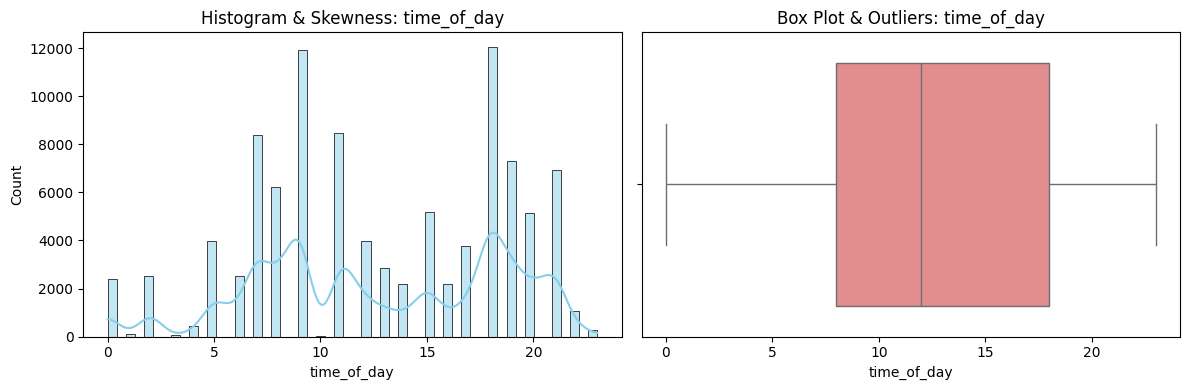

### 📊 Statistik Kuantitatif

,Value
Count (Valid),100000.000000
Mean,12.7702
Median,12.0000
Std Dev,5.7486
Min,0.0000
Max,23.0000
Skewness,-0.1847
Kurtosis,-1.0219


### 🧠 Analisis & Insight

- Skewness berada dalam rentang normal (-0.18). Distribusi relatif simetris di sekitar Mean/Median.
- Kurtosis (-1.02) negatif (**Platykurtik**), menunjukkan ekor yang 'ringan' dan distribusi yang lebih datar (variasi yang lebih tersebar) daripada distribusi normal.
- Tidak terdeteksi adanya *outlier* signifikan berdasarkan aturan 1.5x IQR.

## transaction_duration


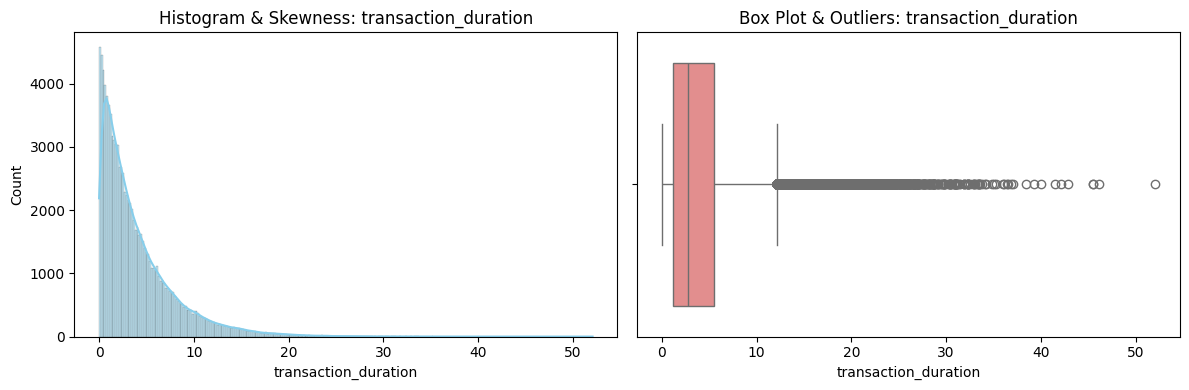

### 📊 Statistik Kuantitatif

,Value
Count (Valid),100000.000000
Mean,3.9996
Median,2.7600
Std Dev,4.0128
Min,0.0000
Max,52.0700
Skewness,2.0212
Kurtosis,6.2485


### 🧠 Analisis & Insight

- Data memiliki **Skewness Positif** tinggi (2.02). Distribusi miring ke kanan, mengindikasikan adanya nilai tinggi (ekor kanan) yang menarik Mean (4.00) di atas Median (2.76). **Normalisasi** disarankan.
- Kurtosis (6.25) tinggi (**Leptokurtik**), menunjukkan ekor yang 'berat' dan puncak yang lebih tajam dari distribusi normal. Ini sering dikaitkan dengan adanya *outlier* ekstrem.
- Terdapat **4903 outlier** (sekitar 4.90%) terdeteksi di luar batas IQR. Nilai Min/Max Outlier adalah 12.13 dan 52.07. Perlu dipertimbangkan *capping* atau *transformasi*.

## num_prev_transactions


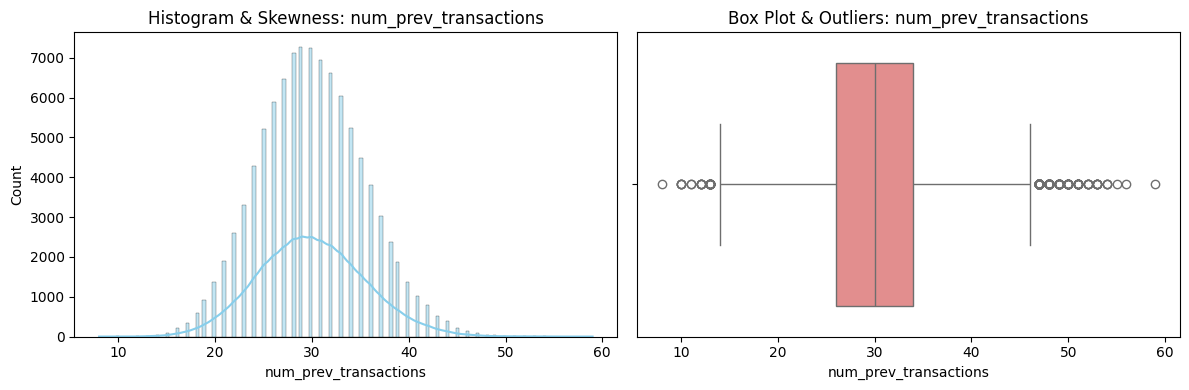

### 📊 Statistik Kuantitatif

,Value
Count (Valid),100000.000000
Mean,29.9921
Median,30.0000
Std Dev,5.4862
Min,8.0000
Max,59.0000
Skewness,0.1795
Kurtosis,0.0308


### 🧠 Analisis & Insight

- Skewness berada dalam rentang normal (0.18). Distribusi relatif simetris di sekitar Mean/Median.
- Terdapat **264 outlier** (sekitar 0.26%) terdeteksi di luar batas IQR. Nilai Min/Max Outlier adalah 8.00 dan 59.00. Perlu dipertimbangkan *capping* atau *transformasi*.

## avg_transaction_amount


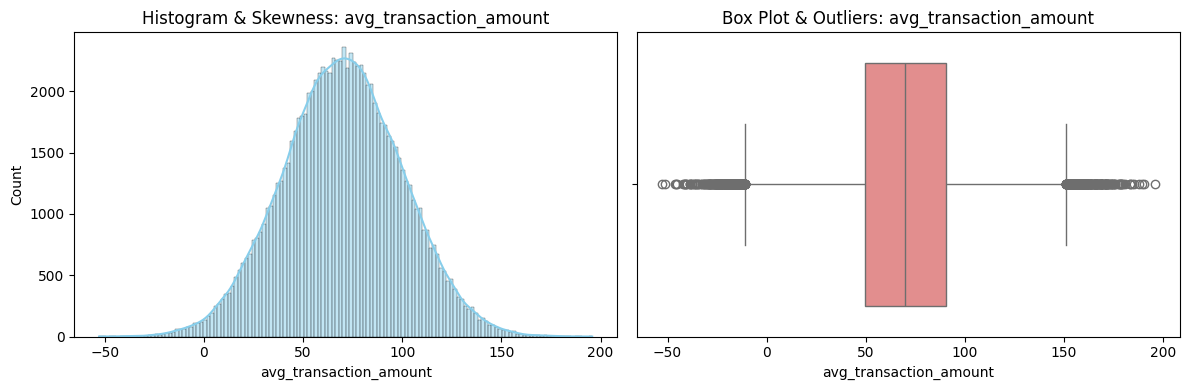

### 📊 Statistik Kuantitatif

,Value
Count (Valid),97581.000000
Mean,69.9697
Median,69.9900
Std Dev,29.9615
Min,-52.8900
Max,195.7900
Skewness,-0.0008
Kurtosis,-0.0348


### 🧠 Analisis & Insight

- Skewness berada dalam rentang normal (-0.00). Distribusi relatif simetris di sekitar Mean/Median.
- Kurtosis (-0.03) negatif (**Platykurtik**), menunjukkan ekor yang 'ringan' dan distribusi yang lebih datar (variasi yang lebih tersebar) daripada distribusi normal.
- Terdapat **655 outlier** (sekitar 0.67%) terdeteksi di luar batas IQR. Nilai Min/Max Outlier adalah -52.89 dan 195.79. Perlu dipertimbangkan *capping* atau *transformasi*.

## std_transaction_amount


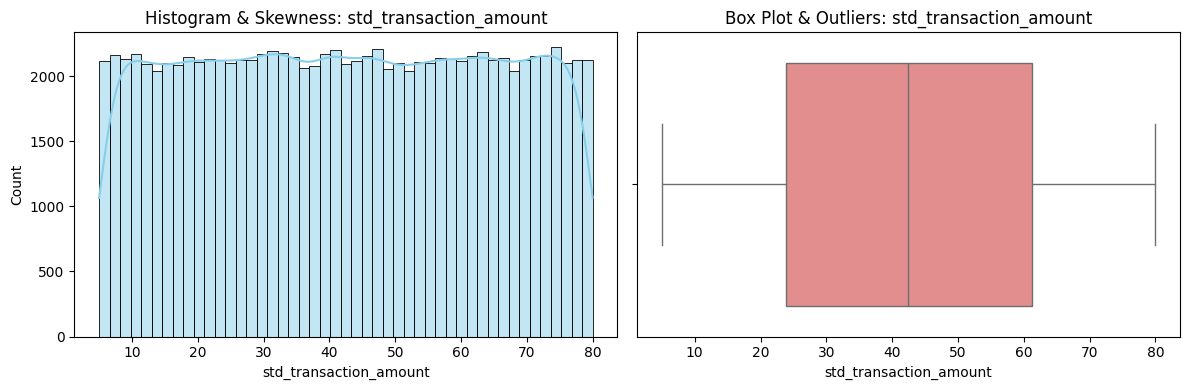

### 📊 Statistik Kuantitatif

,Value
Count (Valid),100000.000000
Mean,42.5412
Median,42.4800
Std Dev,21.6528
Min,5.0000
Max,80.0000
Skewness,-0.0008
Kurtosis,-1.1988


### 🧠 Analisis & Insight

- Skewness berada dalam rentang normal (-0.00). Distribusi relatif simetris di sekitar Mean/Median.
- Kurtosis (-1.20) negatif (**Platykurtik**), menunjukkan ekor yang 'ringan' dan distribusi yang lebih datar (variasi yang lebih tersebar) daripada distribusi normal.
- Tidak terdeteksi adanya *outlier* signifikan berdasarkan aturan 1.5x IQR.

## transactions_last_24h


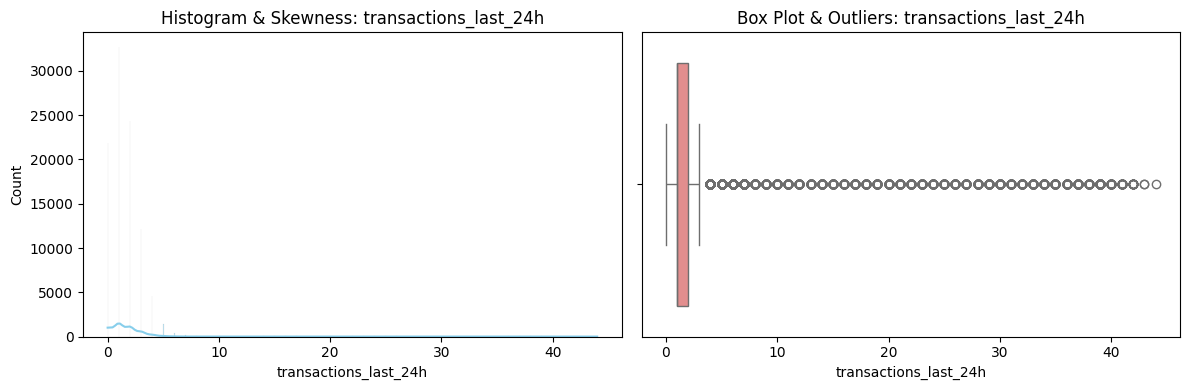

### 📊 Statistik Kuantitatif

,Value
Count (Valid),100000.000000
Mean,2.0402
Median,1.0000
Std Dev,3.9674
Min,0.0000
Max,44.0000
Skewness,6.5813
Kurtosis,49.2692


### 🧠 Analisis & Insight

- Data memiliki **Skewness Positif** tinggi (6.58). Distribusi miring ke kanan, mengindikasikan adanya nilai tinggi (ekor kanan) yang menarik Mean (2.04) di atas Median (1.00). **Normalisasi** disarankan.
- Kurtosis (49.27) tinggi (**Leptokurtik**), menunjukkan ekor yang 'berat' dan puncak yang lebih tajam dari distribusi normal. Ini sering dikaitkan dengan adanya *outlier* ekstrem.
- Terdapat **8878 outlier** (sekitar 8.88%) terdeteksi di luar batas IQR. Nilai Min/Max Outlier adalah 4.00 dan 44.00. Perlu dipertimbangkan *capping* atau *transformasi*.

## transactions_last_1h


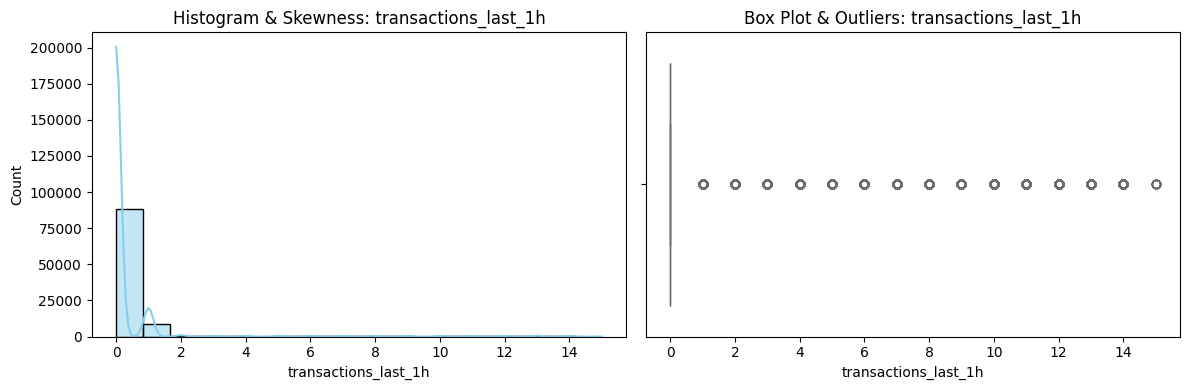

### 📊 Statistik Kuantitatif

,Value
Count (Valid),100000.000000
Mean,0.3092
Median,0.0000
Std Dev,1.4642
Min,0.0000
Max,15.0000
Skewness,6.9142
Kurtosis,51.2270


### 🧠 Analisis & Insight

- Data memiliki **Skewness Positif** tinggi (6.91). Distribusi miring ke kanan, mengindikasikan adanya nilai tinggi (ekor kanan) yang menarik Mean (0.31) di atas Median (0.00). **Normalisasi** disarankan.
- Kurtosis (51.23) tinggi (**Leptokurtik**), menunjukkan ekor yang 'berat' dan puncak yang lebih tajam dari distribusi normal. Ini sering dikaitkan dengan adanya *outlier* ekstrem.
- Terdapat **11697 outlier** (sekitar 11.70%) terdeteksi di luar batas IQR. Nilai Min/Max Outlier adalah 1.00 dan 15.00. Perlu dipertimbangkan *capping* atau *transformasi*.

## failed_login_attempts


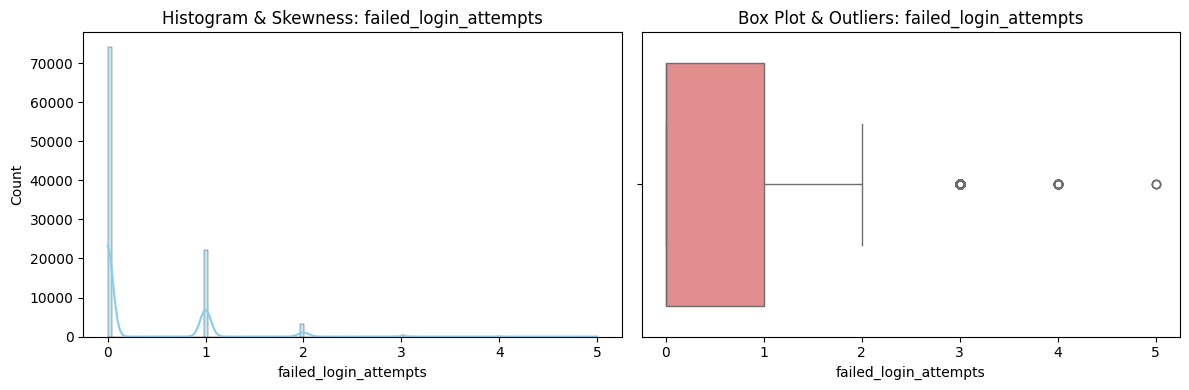

### 📊 Statistik Kuantitatif

,Value
Count (Valid),100000.000000
Mean,0.2981
Median,0.0000
Std Dev,0.5462
Min,0.0000
Max,5.0000
Skewness,1.8421
Kurtosis,3.4624


### 🧠 Analisis & Insight

- Data memiliki **Skewness Positif** tinggi (1.84). Distribusi miring ke kanan, mengindikasikan adanya nilai tinggi (ekor kanan) yang menarik Mean (0.30) di atas Median (0.00). **Normalisasi** disarankan.
- Kurtosis (3.46) tinggi (**Leptokurtik**), menunjukkan ekor yang 'berat' dan puncak yang lebih tajam dari distribusi normal. Ini sering dikaitkan dengan adanya *outlier* ekstrem.
- Terdapat **363 outlier** (sekitar 0.36%) terdeteksi di luar batas IQR. Nilai Min/Max Outlier adalah 3.00 dan 5.00. Perlu dipertimbangkan *capping* atau *transformasi*.

## ip_risk_score


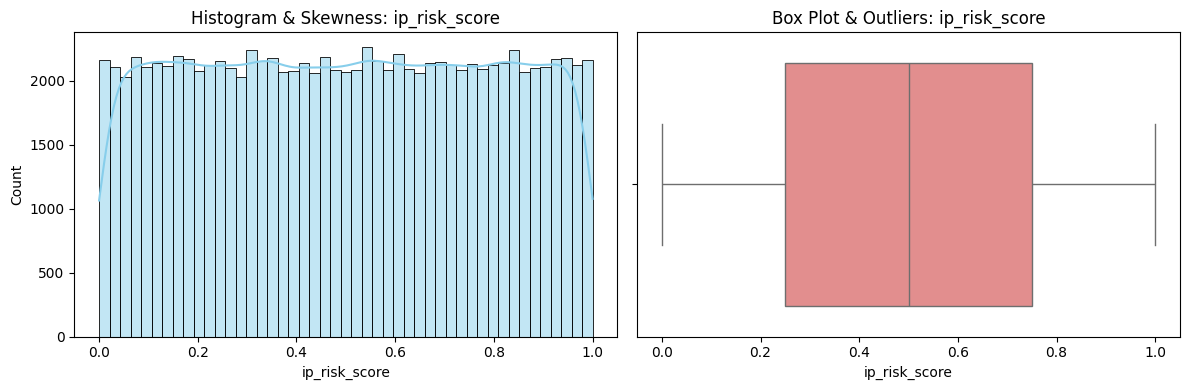

### 📊 Statistik Kuantitatif

,Value
Count (Valid),100000.000000
Mean,0.5004
Median,0.5010
Std Dev,0.2889
Min,0.0000
Max,1.0000
Skewness,-0.0001
Kurtosis,-1.2017


### 🧠 Analisis & Insight

- Skewness berada dalam rentang normal (-0.00). Distribusi relatif simetris di sekitar Mean/Median.
- Kurtosis (-1.20) negatif (**Platykurtik**), menunjukkan ekor yang 'ringan' dan distribusi yang lebih datar (variasi yang lebih tersebar) daripada distribusi normal.
- Tidak terdeteksi adanya *outlier* signifikan berdasarkan aturan 1.5x IQR.

## device_trust_score


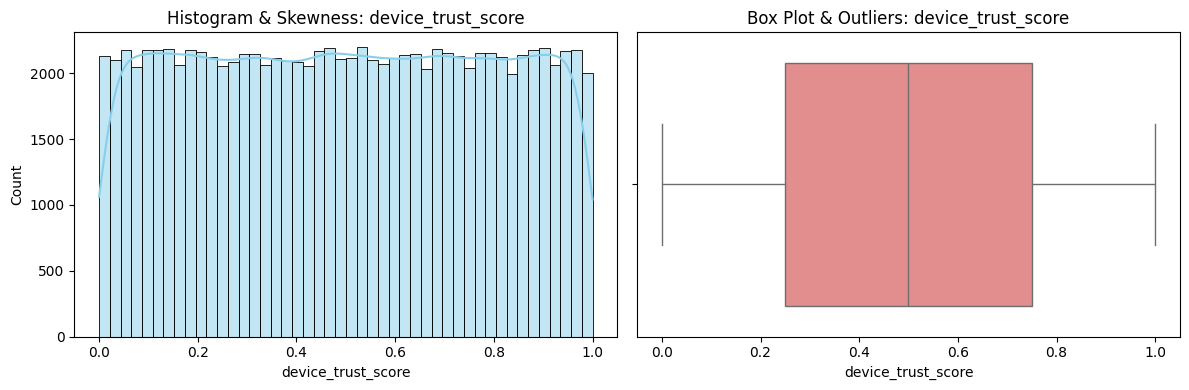

### 📊 Statistik Kuantitatif

,Value
Count (Valid),97581.000000
Mean,0.4995
Median,0.4990
Std Dev,0.2888
Min,0.0000
Max,1.0000
Skewness,0.0006
Kurtosis,-1.2023


### 🧠 Analisis & Insight

- Skewness berada dalam rentang normal (0.00). Distribusi relatif simetris di sekitar Mean/Median.
- Kurtosis (-1.20) negatif (**Platykurtik**), menunjukkan ekor yang 'ringan' dan distribusi yang lebih datar (variasi yang lebih tersebar) daripada distribusi normal.
- Tidak terdeteksi adanya *outlier* signifikan berdasarkan aturan 1.5x IQR.

## account_age_days


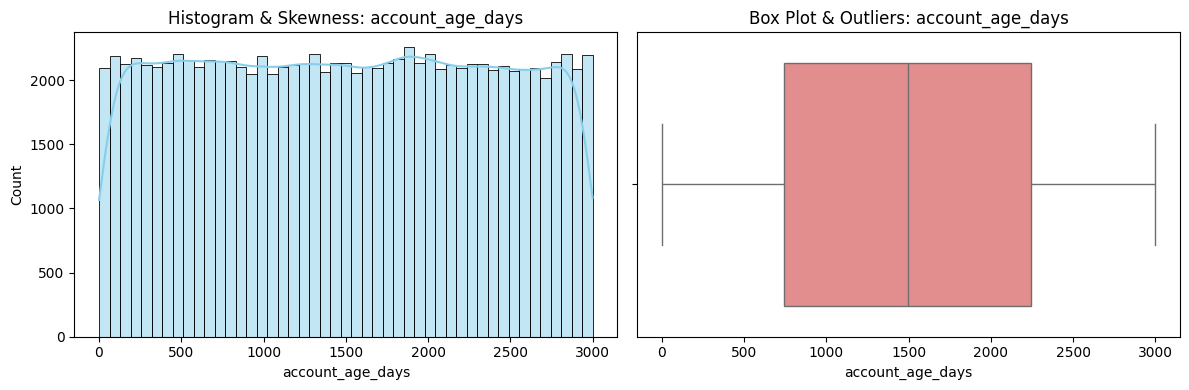

### 📊 Statistik Kuantitatif

,Value
Count (Valid),100000.000000
Mean,1497.3255
Median,1496.0000
Std Dev,866.0043
Min,1.0000
Max,2999.0000
Skewness,0.0047
Kurtosis,-1.1990


### 🧠 Analisis & Insight

- Skewness berada dalam rentang normal (0.00). Distribusi relatif simetris di sekitar Mean/Median.
- Kurtosis (-1.20) negatif (**Platykurtik**), menunjukkan ekor yang 'ringan' dan distribusi yang lebih datar (variasi yang lebih tersebar) daripada distribusi normal.
- Tidak terdeteksi adanya *outlier* signifikan berdasarkan aturan 1.5x IQR.

## shared_ip_users


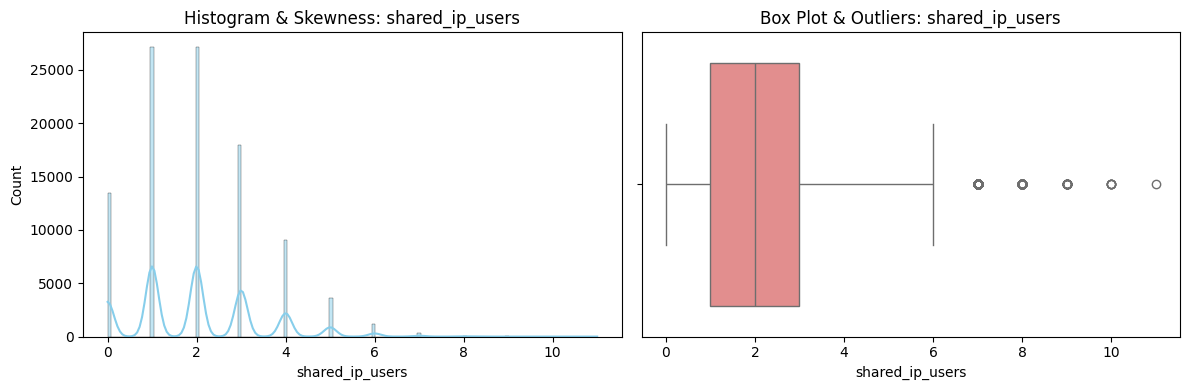

### 📊 Statistik Kuantitatif

,Value
Count (Valid),100000.000000
Mean,2.0008
Median,2.0000
Std Dev,1.4147
Min,0.0000
Max,11.0000
Skewness,0.7205
Kurtosis,0.5564


### 🧠 Analisis & Insight

- Data memiliki **Skewness Positif** tinggi (0.72). Distribusi miring ke kanan, mengindikasikan adanya nilai tinggi (ekor kanan) yang menarik Mean (2.00) di atas Median (2.00). **Normalisasi** disarankan.
- Terdapat **470 outlier** (sekitar 0.47%) terdeteksi di luar batas IQR. Nilai Min/Max Outlier adalah 7.00 dan 11.00. Perlu dipertimbangkan *capping* atau *transformasi*.

## shared_device_users


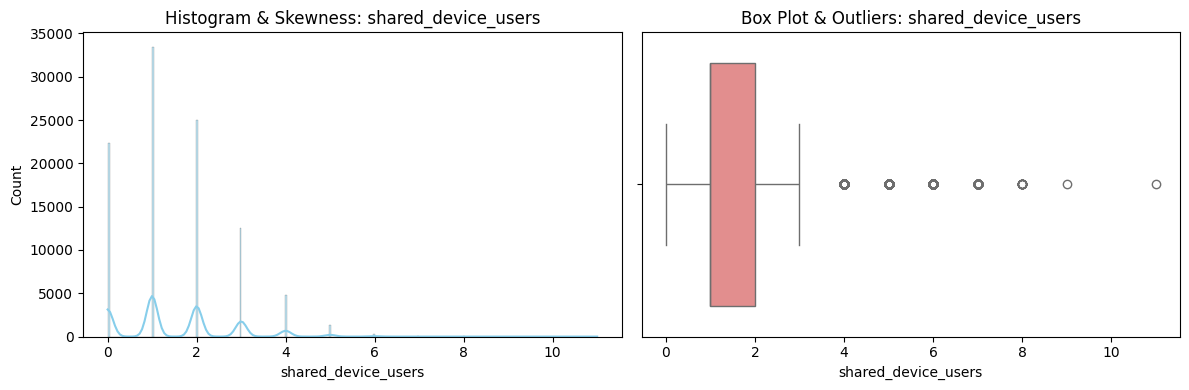

### 📊 Statistik Kuantitatif

,Value
Count (Valid),100000.000000
Mean,1.4998
Median,1.0000
Std Dev,1.2259
Min,0.0000
Max,11.0000
Skewness,0.8162
Kurtosis,0.6671


### 🧠 Analisis & Insight

- Data memiliki **Skewness Positif** tinggi (0.82). Distribusi miring ke kanan, mengindikasikan adanya nilai tinggi (ekor kanan) yang menarik Mean (1.50) di atas Median (1.00). **Normalisasi** disarankan.
- Terdapat **6612 outlier** (sekitar 6.61%) terdeteksi di luar batas IQR. Nilai Min/Max Outlier adalah 4.00 dan 11.00. Perlu dipertimbangkan *capping* atau *transformasi*.

## merchant_risk


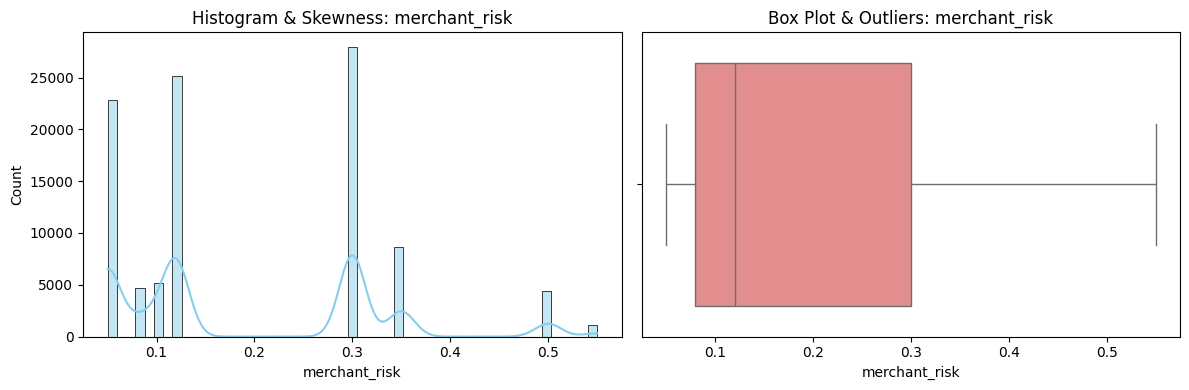

### 📊 Statistik Kuantitatif

,Value
Count (Valid),100000.000000
Mean,0.1930
Median,0.1200
Std Dev,0.1340
Min,0.0500
Max,0.5500
Skewness,0.6585
Kurtosis,-0.5975


### 🧠 Analisis & Insight

- Data memiliki **Skewness Positif** tinggi (0.66). Distribusi miring ke kanan, mengindikasikan adanya nilai tinggi (ekor kanan) yang menarik Mean (0.19) di atas Median (0.12). **Normalisasi** disarankan.
- Kurtosis (-0.60) negatif (**Platykurtik**), menunjukkan ekor yang 'ringan' dan distribusi yang lebih datar (variasi yang lebih tersebar) daripada distribusi normal.
- Tidak terdeteksi adanya *outlier* signifikan berdasarkan aturan 1.5x IQR.

## country_risk


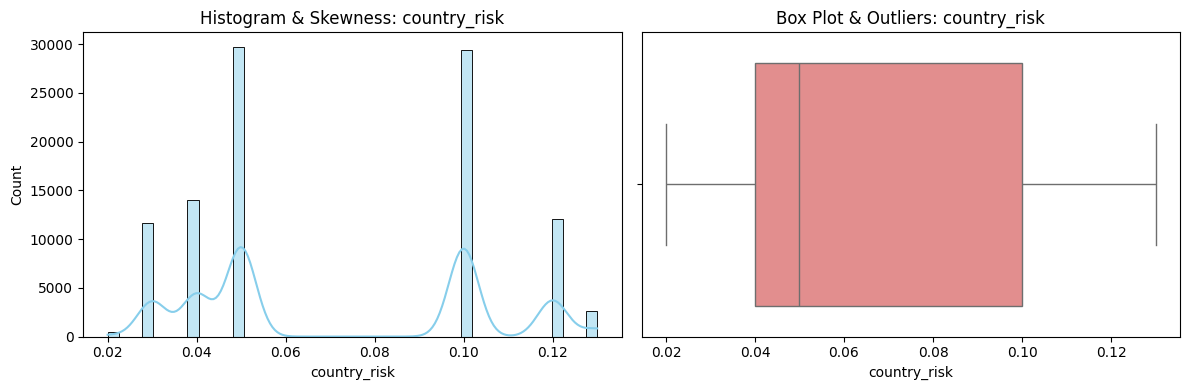

### 📊 Statistik Kuantitatif

,Value
Count (Valid),100000.000000
Mean,0.0713
Median,0.0500
Std Dev,0.0332
Min,0.0200
Max,0.1300
Skewness,0.2728
Kurtosis,-1.5554


### 🧠 Analisis & Insight

- Skewness berada dalam rentang normal (0.27). Distribusi relatif simetris di sekitar Mean/Median.
- Kurtosis (-1.56) negatif (**Platykurtik**), menunjukkan ekor yang 'ringan' dan distribusi yang lebih datar (variasi yang lebih tersebar) daripada distribusi normal.
- Tidak terdeteksi adanya *outlier* signifikan berdasarkan aturan 1.5x IQR.

## distance_from_home


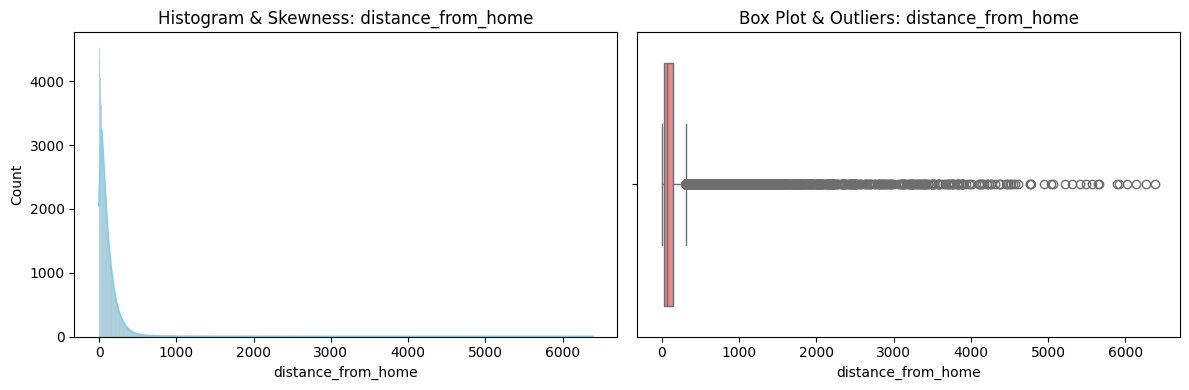

### 📊 Statistik Kuantitatif

,Value
Count (Valid),100000.000000
Mean,117.4116
Median,71.8100
Std Dev,212.0163
Min,0.0000
Max,6388.5176
Skewness,11.3702
Kurtosis,197.8729


### 🧠 Analisis & Insight

- Data memiliki **Skewness Positif** tinggi (11.37). Distribusi miring ke kanan, mengindikasikan adanya nilai tinggi (ekor kanan) yang menarik Mean (117.41) di atas Median (71.81). **Normalisasi** disarankan.
- Kurtosis (197.87) tinggi (**Leptokurtik**), menunjukkan ekor yang 'berat' dan puncak yang lebih tajam dari distribusi normal. Ini sering dikaitkan dengan adanya *outlier* ekstrem.
- Terdapat **5550 outlier** (sekitar 5.55%) terdeteksi di luar batas IQR. Nilai Min/Max Outlier adalah 316.76 dan 6388.52. Perlu dipertimbangkan *capping* atau *transformasi*.

In [13]:
for col in num_list:
    if col == "id": continue

    series = train[col].dropna()

    if series.empty:
        display(Markdown(f"## {col} (Data Kosong/NaN)\n"))
        print("Kolom ini tidak memiliki data valid untuk dianalisis.")
        continue

    # Print Judul
    display(Markdown(f"## {col}\n"))

    # 1. VISUALISASI SKEWNESS (HISTOGRAM + KDE) & OUTLIER (BOX PLOT)
    plt.figure(figsize=(12, 4))

    # Subplot 1: Histogram
    plt.subplot(1, 2, 1)
    sns.histplot(series, kde=True, color='skyblue')
    plt.title(f'Histogram & Skewness: {col}')

    # Subplot 2: Box Plot
    plt.subplot(1, 2, 2)
    sns.boxplot(x=series, color='lightcoral')
    plt.title(f'Box Plot & Outliers: {col}')

    plt.tight_layout()
    plt.show()

    # ============================================
    # DATA ANGKA & INSIGHT (Tambahan Baru)
    # ============================================

    # Hitung Statistik Kuantitatif
    skewness = skew(series)
    kurt = kurtosis(series)

    stats_data = {
        'Count (Valid)': [len(series)],
        'Mean': [series.mean()],
        'Median': [series.median()],
        'Std Dev': [series.std()],
        'Min': [series.min()],
        'Max': [series.max()],
        'Skewness': [skewness],
        'Kurtosis': [kurt],
    }
    stats_df = pd.DataFrame(stats_data).T.rename(columns={0: 'Value'})

    # Format Angka (MODIFIKASI: Gunakan .style.format() untuk display)
    display(Markdown("### 📊 Statistik Kuantitatif"))

    # List index yang ingin diformat
    format_indices = ['Mean', 'Median', 'Std Dev', 'Min', 'Max', 'Skewness', 'Kurtosis']

    # Tampilkan dengan formatting 4 desimal pada subset yang diinginkan
    # Kolom 'Count (Valid)' akan tetap sebagai float/integer
    display(
        stats_df.style.format(
            {'Value': '{:.4f}'}, # Terapkan format 4 desimal ke kolom 'Value'
            subset=pd.IndexSlice[format_indices, ['Value']]
        )
    )

    # --- INSIGHT TEKSTUAL ---
    display(Markdown("### 🧠 Analisis & Insight"))

    insights = []

    # Insight 1: Skewness (Kemiringan)
    # Gunakan nilai numerik asli dari series.mean() dan series.median() untuk inside
    if skewness > 0.5:
        insights.append(f"Data memiliki **Skewness Positif** tinggi ({skewness:.2f}). Distribusi miring ke kanan, mengindikasikan adanya nilai tinggi (ekor kanan) yang menarik Mean ({series.mean():.2f}) di atas Median ({series.median():.2f}). **Normalisasi** disarankan.")
    elif skewness < -0.5:
        insights.append(f"Data memiliki **Skewness Negatif** tinggi ({skewness:.2f}). Distribusi miring ke kiri, mengindikasikan adanya nilai rendah (ekor kiri) yang menarik Mean ({series.mean():.2f}) di bawah Median ({series.median():.2f}). **Normalisasi** mungkin diperlukan.")
    else:
        insights.append(f"Skewness berada dalam rentang normal ({skewness:.2f}). Distribusi relatif simetris di sekitar Mean/Median.")

    # Insight 2: Kurtosis (Puncak)
    if kurt > 3.0:
        insights.append(f"Kurtosis ({kurt:.2f}) tinggi (**Leptokurtik**), menunjukkan ekor yang 'berat' dan puncak yang lebih tajam dari distribusi normal. Ini sering dikaitkan dengan adanya *outlier* ekstrem.")
    elif kurt < 0.0:
        insights.append(f"Kurtosis ({kurt:.2f}) negatif (**Platykurtik**), menunjukkan ekor yang 'ringan' dan distribusi yang lebih datar (variasi yang lebih tersebar) daripada distribusi normal.")

    # Insight 3: Outlier
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers_mask = (series < lower_bound) | (series > upper_bound)
    outliers_count = outliers_mask.sum()

    if outliers_count > 0:
        outliers_series = series[outliers_mask]
        insights.append(f"Terdapat **{outliers_count} outlier** (sekitar {(outliers_count/len(series))*100:.2f}%) terdeteksi di luar batas IQR. Nilai Min/Max Outlier adalah {outliers_series.min():.2f} dan {outliers_series.max():.2f}. Perlu dipertimbangkan *capping* atau *transformasi*.")
    else:
        insights.append("Tidak terdeteksi adanya *outlier* signifikan berdasarkan aturan 1.5x IQR.")

    display(Markdown("- " + "\n- ".join(insights)))
    print("\n" + "="*80 + "\n") # Pemisah antar kolom

#### 3. Visualize the correlation between features and the target variable.

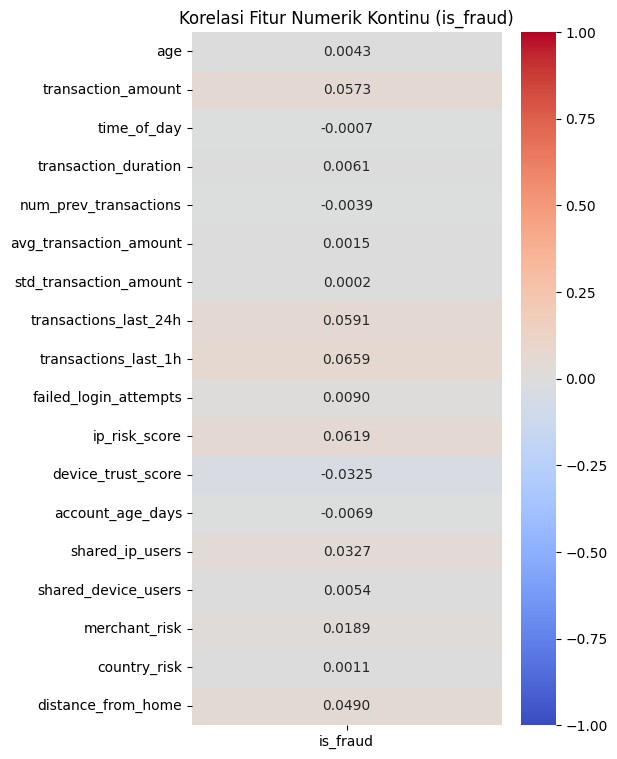

In [14]:
target_col = 'is_fraud'
correlation_columns = num_list + [target_col]

# 1. Hitung Matriks Korelasi (Hanya untuk fitur numerik kontinu dan target)
corr_matrix = train[correlation_columns].corr()

# 2. Ambil Korelasi Fitur vs Target
corr_feature_target = corr_matrix[[target_col]].drop(index=target_col)

# 3. Plotting Heatmap
plt.figure(figsize=(5, max(5, len(corr_feature_target) * 0.5)))
sns.heatmap(corr_feature_target, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.4f')
plt.title(f'Korelasi Fitur Numerik Kontinu ({target_col})')
plt.show()

#### 4. Explain the significance of understanding feature distributions and correlations.

Pemahaman mengenai distribusi fitur dan korelasi antar fitur sangat penting untuk memperoleh wawasan tentang bagaimana **data saling berhubungan dan keterkaitan data** pada masalah yang ingin dipecahkan. **Korelasi antar fitur** dapat membantu **mengidentifikasi hubungan yang signifikan dan mengetahui variabel yang berperan dalam model prediksi**. **Visualisasi distribusi** setiap fitur, baik kategorikal maupun non-kategorikal, **memberikan gambaran tentang karakteristik data**, seperti apakah fitur memiliki distribusi normal atau terdapat outlier yang perlu diperhatikan. Sementara itu, **visualisasi korelasi antara fitur dan variabel target** memungkinkan untuk **mengidentifikasi pengaruh variabel independen terhadap variabel dependen**, sehingga dapat membantu dalam pemilihan fitur yang relevan untuk pembuatan model dan strategi analisis yang lebih tepat.

## B. Data Insights

The objective of this section is for participants to understand how to formulate and get many insights from the given data so that we can improve the model performance. Given example questions:

1.How does fraud proportion differ across geo-location indicators like is_new_country or device categories?

2.Are fraud cases meaningfully correlated with user and transaction behavior patterns?

3.Which behavioral or environmental features exhibit different distributions across fraud vs non-fraud classes?

### Step 1

Answer the three example questions by visualizing and explaining the insights for each question. Add markdown texts to explain the visualizations.

#### 1. How do fraud and non-fraud cases differ when segmented by is_new_country and device_type?(`is_new_country` and `device type`)?

In [15]:
colors = {'0': 'orange', '1': 'blue', 'NaN': 'grey'}

# === Plot 1: is_new_country vs fraud ===
country_counts = df.groupby(['is_new_country', 'is_fraud']).size().unstack(fill_value=0)
ax = country_counts.plot(
    kind='bar',
    stacked=True,
    color=[colors[str(i)] for i in country_counts.columns],
    figsize=(5, 3)
)
plt.title('Fraud vs Non-Fraud based on New Country Flag', fontsize=10)
plt.xlabel('is_new_country')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.legend(title='Label', labels=['Non-Fraud (0)', 'Fraud (1)'], loc='upper left', fontsize=6)

# ADD LABELS
for container in ax.containers:
    ax.bar_label(container, fmt='%d', fontsize=6, label_type='center')

plt.show()

# === Plot 2: device_type vs fraud ===
device_counts = df.groupby(['device_type', 'is_fraud']).size().unstack(fill_value=0)
ax = device_counts.plot(
    kind='bar',
    stacked=True,
    color=[colors[str(i)] for i in device_counts.columns],
    figsize=(5, 3)
)
plt.title('Fraud vs Non-Fraud based on Device Type', fontsize=10)
plt.xlabel('device_type')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.legend(title='Label', labels=['Non-Fraud (0)', 'Fraud (1)'], loc='upper left', fontsize=6)

for container in ax.containers:
    ax.bar_label(container, fmt='%d', fontsize=6, label_type='center')

plt.show()

# === Plot 3: merchant_risk vs fraud ===
merchant_counts = df.groupby(['merchant_risk', 'is_fraud']).size().unstack(fill_value=0)
ax = merchant_counts.plot(
    kind='bar',
    stacked=True,
    color=[colors[str(i)] for i in merchant_counts.columns],
    figsize=(5, 3)
)

plt.title('Fraud vs Non-Fraud based on Merchant Risk', fontsize=10)
plt.xlabel('merchant_risk')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.legend(title='Label', labels=['Non-Fraud (0)', 'Fraud (1)'], loc='upper left', fontsize=6)

for container in ax.containers:
    ax.bar_label(container, fmt='%d', fontsize=6, label_type='center')

plt.show()

# === Plot 4: country_risk vs fraud ===
country_counts = df.groupby(['country_risk', 'is_fraud']).size().unstack(fill_value=0)
ax = country_counts.plot(
    kind='bar',
    stacked=True,
    color=[colors[str(i)] for i in country_counts.columns],
    figsize=(5, 3)
)

plt.title('Fraud vs Non-Fraud based on Country Risk', fontsize=10)
plt.xlabel('country_risk')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.legend(title='Label', labels=['Non-Fraud (0)', 'Fraud (1)'], loc='upper left', fontsize=6)

for container in ax.containers:
    ax.bar_label(container, fmt='%d', fontsize=6, label_type='center')

plt.show()

# === Plot 5: chargeback history vs fraud ===
chargeback_counts = df.groupby(['has_chargeback_history', 'is_fraud']).size().unstack(fill_value=0)
ax = chargeback_counts.plot(
    kind='bar',
    stacked=True,
    color=[colors[str(i)] for i in chargeback_counts.columns],
    figsize=(5, 3)
)

plt.title('Fraud vs Non-Fraud based on Chargeback History', fontsize=10)
plt.xlabel('has_chargeback_history')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.legend(title='Label', labels=['Non-Fraud (0)', 'Fraud (1)'], loc='upper left', fontsize=6)

for container in ax.containers:
    ax.bar_label(container, fmt='%d', fontsize=6, label_type='center')

plt.show()


NameError: name 'df' is not defined

Berdasarkan hasil analisis, terdapat perbedaan yang signifikan antara URL phishing dan non-phishing pada fitur keamanan seperti IsHTTPS dan Robots.
- Pada fitur IsHTTPS, mayoritas URL non-phishing (label = 1) menggunakan protokol HTTPS (IsHTTPS = 1) yang menunjukkan bahwa URL non-phishing cenderung menggunakan enkripsi untuk melindungi koneksi pengguna. Sebaliknya, URL phishing (label = 0) cenderung tidak menggunakan HTTPS (IsHTTPS = 0) atau memiliki nilai yang tidak tersedia (IsHTTPS = NaN). Hal ini menunjukkan bahwa URL phishing lebih jarang memanfaatkan protokol keamanan seperti HTTPS sehingga fitur ini dapat menjadi indikator dalam menentukan URL phishing dan URL legitimate.
- Pada fitur Robots, URL phishing dan non-phishing pada umumnya tidak menggunakan Robots (Robots = 0). Selain itu, baik URL phishing maupun non-phishing ada yang menggunakan robot (Robots = 1), ada yang tidak menggunakan robot (Robots = 0), serta ada yang tidak tersedia (Robots = NaN). Oleh karena itu, penggunaan robot atau tidak belum mampu memberikan informasi tambahan dalam membedakan URL phishing maupun non-phishing.

Secara keseluruhan, fitur **IsHTTPS** dapat digunakan untuk membedakan URL phishing dan non-phishing sedangkan fitur **Robots** belum dapat memberikan informasi yang signifikan.

#### 2. Is there a significant correlation between the label of a transaction (fraud or non-fraud) and its transaction characteristics?

Transaction Characteristics:
- `transaction_amount`
- `transaction_type`
- `time_of_day`
- `day_of_week`
- `transaction_duration`
- `num_prev_transactions`
- `avg_transaction_amount`
- `std_transaction_amount`
- `transactions_last_24h`
- `transactions_last_1h`
- `account_age_days`
- `has_chargeback_history`
- `failed_login_attempts`
- `shared_ip_users`
- `shared_device_users`
- `device_type`
- `device_os`
- `device_trust_score`
- `ip_risk_score`
- `country`
- `country_risk`
- `distance_from_home`
- `is_new_country`
- `merchant_category`
- `merchant_risk`

In [ ]:
# daftar fitur numerik yang mau dicek terhadap label is_fraud
fraud_numeric_features = [
    "transaction_amount",
    "avg_transaction_amount",
    "std_transaction_amount",
    "device_trust_score",
    "ip_risk_score",
    "distance_from_home",
    "num_prev_transactions",
    "transactions_last_24h",
    "transactions_last_1h",
    "failed_login_attempts",
    "account_age_days",
    "time_of_day",
    "day_of_week",
    "transaction_duration",
    "shared_ip_users",
    "shared_device_users",
    "merchant_risk",
    "country_risk",
    "age"
]

plt.figure(figsize=(20, 20))
plt.suptitle(
    "Distribution of Numeric Fraud Features by Label\n(0 = Non-Fraud, 1 = Fraud)",
    fontsize=20
)

for i, feature in enumerate(fraud_numeric_features, 1):
    plt.subplot(5, 4, i)
    sns.boxplot(
        data=df,
        x="is_fraud",
        y=feature,
        hue="is_fraud",
        palette={0: "orange", 1: "blue"},
        showfliers=False
    )
    plt.title(feature)
    plt.xlabel("is_fraud")
    plt.ylabel(feature)
    plt.legend([],[], frameon=False)  #legend di setiap subplot ga dipake sehingga tidak terlalu padat

plt.tight_layout()
plt.subplots_adjust(top=0.90)
plt.show()


Berdasarkan analisis yang telah dilakukan, didapatkan hasil sebagai berikut.
- Fitur **URLLength**: URL phishing cenderung memiliki panjang URL lebih besar dibandingkan URL legitimate. Hal ini terlihat dari nilai rata-rata dan distribusi URLLength pada label 0 lebih tinggi dibanding label 1. Mayoritas panjang URL pada label phishing berkisar dari 20an hingga 40an dengan nilai tengah 30an. Berbeda dengan panjang URL untuk label legitimate yang cenderung lebih pendek dengan mayoritas 20an.
- Fitur **Domain**: Beberapa domain dan kategori domain lebih sering muncul pada URL non-phishing dibandingkan phishing. Misalnya, domain dengan kategori "Generic TLD", "Country Code TLD" atau "Other" lebih dominan pada URL non-phishing.
- Fitur **DomainLength**: URL phishing cenderung memiliki panjang URL lebih besar dibandingkan URL legitimate. Hal ini terlihat dari nilai rata-rata dan distribusi DomainLength pada label 0 lebih tinggi dibanding label 1. Mayoritas panjang URL pada label phishing berkisar dari 15 hingga 30 dengan nilai tengah 20an. Berbeda dengan panjang URL untuk label legitimate yang cenderung lebih pendek dengan mayoritas 15 sampai 20.
- Fitur **IsDomainIP**: Tidak ada perbedaan signifikan antara label 0 dan 1 untuk fitur ini karena mayoritas nilai IsDomainIP mendekati nilai 0. Hal ini menunjukkan bahwa penggunaan IsDomainIP tidak dapat menjadi indikator pembeda antara phishing dan legitimate.
- Fitur **TLD**: URL phishing cenderung menggunakan TLD tertentu seperti TLD generik atau tidak dikenal. Legitimate URL lebih sering menggunakan TLD populer seperti .com atau .org.
- Fitur **TLDLength**: Panjang TLD tidak menunjukkan perbedaan yang sangat signifikan antara kedua label, meskipun URL non-phishing cenderung memiliki panjang TLD yang sedikit lebih besar
- Fitur **NoOfSubDomain**: Tidak ada perbedaan signifikan antara label 0 dan 1 untuk fitur ini karena mayoritas nilai IsDomainIP mendekati nilai 1. Hal ini menunjukkan bahwa penggunaan IsDomainIP tidak dapat menjadi indikator pembeda antara phishing dan legitimate.
- Fitur **HasObfuscation**: Tidak ada perbedaan signifikan antara label 0 dan 1 untuk fitur ini karena mayoritas nilai IsDomainIP mendekati nilai 0. Hal ini menunjukkan bahwa penggunaan IsDomainIP tidak dapat menjadi indikator pembeda antara phishing dan legitimate.
- Fitur **NoOfObfuscatedChar**: Tidak ada perbedaan signifikan antara label 0 dan 1 untuk fitur ini karena mayoritas nilai IsDomainIP mendekati nilai 0. Hal ini menunjukkan bahwa penggunaan IsDomainIP tidak dapat menjadi indikator pembeda antara phishing dan legitimate.
- Fitur **ObfuscationRatio**: Tidak ada perbedaan signifikan antara label 0 dan 1 untuk fitur ini karena mayoritas nilai IsDomainIP mendekati nilai 0. Hal ini menunjukkan bahwa penggunaan IsDomainIP tidak dapat menjadi indikator pembeda antara phishing dan legitimate.
- Fitur **NoOfLettersInURL**: URL phishing cenderung memiliki lebih banyak huruf dibandingkan URL legitimate. Hal ini terlihat dari nilai rata-rata dan distribusi DomainLength pada label 0 lebih tinggi dibanding label 1. Mayoritas panjang URL pada label phishing berkisar dari 12 hingga 30 dengan nilai tengah 20. Berbeda dengan panjang URL untuk label legitimate yang cenderung lebih pendek dengan mayoritas 9 sampai 15.
- Fitur **LetterRatioInURL**: URL phishing cenderung memiliki rasio huruf terhadap total panjang URL lebih besar dibandingkan URL legitimate. Hal ini terlihat dari nilai rata-rata dan distribusi DomainLength pada label 0 lebih tinggi dibanding label 1. Mayoritas panjang URL pada label phishing berkisar dari 0.5 hingga 0.68 dengan nilai tengah 0.58. Berbeda dengan panjang URL untuk label legitimate yang cenderung lebih pendek dengan mayoritas 0.4 sampai 0.55.
- Fitur **NoOfDegitsInURL**: Sebagian besar URL legitimate tidak memiliki digit yang banyak karena mendekati nilai 0. Sebaliknya, URL phishing memiliki persebaran data dari 0 hingga 433 dengan nilai mayoritas dari 0 hingga 5.
- Fitur **DegitsRatioInURL**: Sebagian besar URL legitimate tidak memiliki rasio digit yang panjang karena mendekati nilai 0. Sebaliknya, URL phishing memiliki persebaran data dari 0 hingga 0.6 dengan nilai mayoritas dari 0 hingga 0.1.
- Fitur **NoOfEqualsInURL**: Tidak ada perbedaan signifikan antara label 0 dan 1 untuk fitur ini karena mayoritas nilai IsDomainIP mendekati nilai 0. Hal ini menunjukkan bahwa penggunaan IsDomainIP tidak dapat menjadi indikator pembeda antara phishing dan legitimate.
- Fitur **NoOfQMarkInURL**: Tidak ada perbedaan signifikan antara label 0 dan 1 untuk fitur ini karena mayoritas nilai IsDomainIP mendekati nilai 0. Hal ini menunjukkan bahwa penggunaan IsDomainIP tidak dapat menjadi indikator pembeda antara phishing dan legitimate.
- Fitur **NoOfAmpersandInURL**: Tidak ada perbedaan signifikan antara label 0 dan 1 untuk fitur ini karena mayoritas nilai IsDomainIP mendekati nilai 0. Hal ini menunjukkan bahwa penggunaan IsDomainIP tidak dapat menjadi indikator pembeda antara phishing dan legitimate.
- Fitur **NoOfOtherSpecialCharInURL**: Sebagian besar URL legitimate tidak memiliki karakter khusus lainnya karena mendekati nilai 1. Sebaliknya, URL phishing memiliki persebaran data mayoritas dari 2 sampai 5.
- Fitur **SpecialCharRatioInURL**: URL phishing cenderung memiliki panjang URL lebih besar dibandingkan URL legitimate. Hal ini terlihat dari nilai rata-rata dan distribusi URLLength pada label 0 lebih tinggi dibanding label 1. Mayoritas panjang URL pada label phishing berkisar dari 0.05 hingga 0.1 dengan nilai tengah 0.8. Berbeda dengan panjang URL untuk label legitimate yang cenderung lebih pendek dengan mayoritas berada pada kisaran 0.05.
- Fitur **CharContinuationRate**: Sebagian besar URL legitimate memiliki tingkat kesinambungan karakter yang tinggi karena mendekati nilai 1. Sebaliknya, URL phishing memiliki persebaran data dengan nilai mayoritas dari 0.5 hingga 1.

Secara keseluruhan, fitur yang ada selain IsDomainIP, NoOfSubDomain, HasObfuscation, NoOfObfuscatedChar, ObfuscationRatio, NoOfEqualsInURL, NoOfQMarkInURL, dan NoOfAmpersandInURL perlu digunakan bersama untuk dapat membedakan URL phishing dan non-phising.

#### 3. How does website-resource-related features vary across phishing and non-phishing URLs?

Website resource related features:
- `NoOfImage`
- `NoOfCSS`
- `NoOfJS`
- `NoOfSelfRef`
- `NoOfEmptyRef`
- `NoOfExternalRef`

In [ ]:
# fraud dataset resource-like feature list
fraud_resource_features = [
    'transactions_last_24h',
    'transactions_last_1h',
    'failed_login_attempts',
    'num_prev_transactions',
    'shared_ip_users',
    'shared_device_users'
]

# Set figure size and title
plt.figure(figsize=(15, 10))
plt.suptitle(
    "Transaction / Behavior Resource Features by Fraud Label\n(0 = Non-Fraud: Orange, 1 = Fraud: Blue)",
    fontsize=16
)

#create box plots
for i, feature in enumerate(fraud_resource_features, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(
        data=df,
        x='is_fraud',
        y=feature,
        hue='is_fraud',
        palette={0: 'orange', 1: 'blue'},
        showfliers=False
    )
    plt.title(feature)
    plt.xlabel("is_fraud")
    plt.ylabel(feature)
    plt.legend([], [], frameon=False)

plt.tight_layout()
plt.subplots_adjust(top=0.88)
plt.show()


Berdasarkan analisis yang telah dilakukan, didapatkan hasil sebagai berikut.
- Fitur **NoOfImage**: URL phishing cenderung memiliki nilai yang mendekati nol sedangkan URL legitimate memiliki nilai yang beragam dimulai dari 0 hingga 8956 dengan nilai yang paling banyak berada di angka 20an dan persebaran paling banyak di antara 15 hingga 50. Hal ini menunjukkan bahwa situs legitimate lebih sering menggunakan gambar.
- Fitur **NoOfCSS**: URL phishing cenderung memiliki nilai yang mendekati nol sedangkan URL legitimate memiliki nilai yang beragam dimulai dari 0 hingga 35820 dengan nilai yang paling banyak berada di sela angka 6 atau 7 dan persebaran paling banyak di antara 2 hingga 14. Hal ini menunjukkan bahwa situs legitimate mengandung banyak jumlah file CSS.
- Fitur **NoOfJS**: Jumlah file JavaScript pada URL legitimate lebih banyak dibandingkan dengan phishing yang mendekati nilai 0 (tidak memiliki file JS). Jumlah file pada URL legitimate berkisar dari 0 hingga 2828 dengan nilai paling tinggi berada di antara angka 12 dan 13 serta persebaran paling banyak di rentang 8-25.
- Fitur **NoOfSelfRef**: URL legitimate memiliki jumlah referensi ke diri sendiri yang jauh lebih tinggi dengan kisaran 0 hingga 26596 dibandingkan dengan phishing yang hampir selalu mendekati nilai nol. Persebaran nilai jumlah referensi untuk URL legitimate berada di rentang 40an hingga 130an dan modus pada nilai 70an.
- Fitur **NoOfEmptyRef**: Referensi kosong lebih umum pada URL Legitimate, meskipun jumlahnya relatif kecil. Referensi kosong pada URL legitimate lebih banyak berada pada angka 1 dengan kisaran angka 0-3. Hal ini menunjukkan fitur ini kurang signifikan dibandingkan yang lain.
- Fitur **NoOfExternalRef**: URL legitimate memiliki jumlah referensi eksternal dimulai dari 0 hingga 27516 dengan kisaran paling banyak di antara 10an hingga 100 dan modus pada angka 40an.

Kesimpulan: Dari fitur yang ada menunjukkan bahwa URL phishing cenderung minimalis, tanpa adanya gambar, file CSS, JavaScript atau self referensi dan eksternal referensi. Sebaliknya, URL legitimate cenderung memiliki banyak elemen ini.

### Step 2

Try to formulate three other new questions and answer them with the methods used before.

#### 4. How do the features related to form submissions and external interactions relate to phishing and non-phishing URLs?

Website resource related features:
- `HasExternalFormSubmit`
- `HasSocialNet`
- `HasSubmitButton`
- `HasHiddenFields`
- `HasPasswordField`

In [ ]:
fraud_interaction_features = [
    'has_chargeback_history',
    'is_new_country',
    'ip_risk_score',
    'merchant_risk',
    'country_risk'
]

plt.figure(figsize=(15, 10))
plt.suptitle("Relationship Between Interaction / Risk Indicators and Fraud Detection\n(0 = Non-Fraud, 1 = Fraud)", fontsize=16)

for i, feature in enumerate(fraud_interaction_features, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(
        data=df,
        x='is_fraud',
        y=feature,
        hue='is_fraud',
        palette={0: 'orange', 1: 'blue'},
        showfliers=False
    )
    plt.title(feature)
    plt.xlabel("is_fraud")
    plt.ylabel(feature)
    plt.legend([], [], frameon=False)

plt.tight_layout()
plt.subplots_adjust(top=0.88)
plt.show()


Berdasarkan grafik hubungan antar fitur terkait form submissions dan external interactions dengan phishing detection, berikut adalah analisisnya.
- Fitur **HasExternalFormSubmit** menunjukkan bahwa antara URL phising (label = 0) dan non-phishing (label = 1) memperlihatkan data yang banyak ketika tidak memiliki external form submit (HasExternalFormSubmit = 0). Hal ini menunjukkan fitur ini tidak memberikan hasil yang signifikan untuk membedakan antara URL phising dan non-phising.
- Fitur **HasSocialNet** menunjukkan bahwa sebagian besar URL phising tidak memiliki social net (HasSocialNet = 0) dan sebagian besar URL legitimate memiliki social net (HasSocialNet = 1). Hal ini menunjukkan fitur ini dapat digunakan untuk mendeteksi URl phising.
- Fitur **HasSubmitButton** menunjukkan bahwa sebagian besar URL phising tidak memiliki submit button (HasSubmitButton = 0). Sebaliknya, persebaran data antara memiliki submit button atau tidak untuk URL legitimate merata sehingga tidak dapat dideteksi.
- Fitur **HasHiddenFields** menunjukkan bahwa sebagian besar URL phising tidak memiliki hiddden fiels (HasHiddenFields = 0). Sebaliknya, persebaran data antara memiliki hidden fields atau tidak untuk URL legitimate merata sehingga tidak dapat dideteksi.
- Fitur **HasPasswordField** menunjukkan bahwa antara URL phising (label = 0) dan non-phishing (label = 1) memperlihatkan data yang banyak ketika tidak memiliki password field (HasPasswordField = 0). Hal ini menunjukkan fitur ini tidak memberikan hasil yang signifikan untuk membedakan antara URL phising dan non-phising.

Kesimpulan, dari fitur-fitur yang ada, hanya HasSocialNet yang menunjukkan hubungan yang baik untuk mendeteksi URL sedangkan fitur HasHiddenFields dan HasSubmitButton dapat menjadi fitur pendukung untuk mendeteksi URL phishing.

#### 5. How the Correlation Between TLD Legitimacy and URL Character Probability Enhances Phishing Detection?

Domain-related features:
- `TLDLegitimateProb`
- `URLCharProb`

In [ ]:
domain_related_features = ['merchant_risk', 'country_risk']

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("Domain / Environment Risk Features and Fraud Detection", fontsize=16)

axes_flat = axes.flatten()
palette = {0: 'orange', 1: 'blue'}

for i, feature in enumerate(domain_related_features):
    ax = axes_flat[i]
    sns.boxplot(
        x='is_fraud',
        y=feature,
        data=df,
        hue='is_fraud',
        palette=palette,
        showfliers=False,
        ax=ax
    )
    ax.set_title(feature)
    ax.set_xlabel('Label (0 = Non-Fraud, 1 = Fraud)')
    ax.set_ylabel(feature)
    ax.legend(title='is_fraud')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()


Berdasarkan hasil analisis, terdapat dua fitur domain-related yang dianalisis yaitu TLDLegitimateProb dan URLCharProb.
- Fitur **TLDLegitimateProb** tidak menunjukkan perbedaan yang signifikan karena keduanya memiliki persebaran nilai yang merata.
- Fitur **URLCharProb** menunjukkan bahwa URL phishing cenderung memiliki kisaran nilai dari 0.01 hingga 0.1 dengan mayoritas nilai 0.04 hingga 0.06. Sebaliknya, URL legitimate cenderung memiliki kisaran nilai dari 0.04 hingga 0.08 dengan mayoritas nilai sekitaran 0.06.

Secara keseluruhan, kombinasi kedua fitur ini dapat meningkatkan akurasi pendeteksian phishing karena keduanya saling melengkapi.

#### 6. Are there any correlations between webpage metadata features and phishing versus non-phishing URLs?

Webpage Metadata features:
- `HasTitle`
- `HasFavicon`
- `HasDescription`
- `HasCopyright`

In [ ]:
metadata_features = [
    "device_trust_score",
    "ip_risk_score",
    "merchant_risk",
    "country_risk"
]

plt.figure(figsize=(15, 10))
plt.suptitle(
    "Correlation of Environment / Reputation Risk Features by Fraud Label",
    fontsize=16
)

palette = {0: "orange", 1: "blue"}

for idx, feature in enumerate(metadata_features):
    ax = plt.subplot(2, 2, idx + 1)
    sns.boxplot(
        data=df,
        x="is_fraud",
        y=feature,
        hue="is_fraud",
        palette=palette,
        showfliers=False,
        ax=ax
    )
    ax.set_title(feature, fontsize=12)
    ax.set_xlabel("is_fraud", fontsize=10)
    ax.set_ylabel(feature, fontsize=10)
    ax.legend(title="Label", loc="lower right")

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


Berdasarkan grafik hasil analisis, terdapat korelasi signifikan antara webpage metadata dengan klasifikasi URL phishing maupun non-phising. Fitur **HasFavicon dan HasDescription** menunjukkan bahwa sebagian besar URL phishing tidak memiliki favicon (HasFavicon = 0) dan deskripsi (HasDescription = 0) yang merupakan karakteristik umum dari situs web resmi dan tepercaya. Sebaliknya, URL legitimate memiliki persebaran merata antara memiliki favicon dan deskripsi ataupun tidak.

Fitur **HasTitle** menunjukkan sebagian besar URL legitimate memiliki title (HasTitle = 1). Sebalinya, URL phishing memiliki persebaran data yang merata antara memiliki title ataupun tidak. Fitur **HasCopyrightInfo** menunjukkan bahwa sebagian besar URL phising tidak memiliki copyright info (HasCopyrightInfo = 0) dan sebagian besar URL legitimate memiliki copyright info (HasCopyrightInfo = 1). Secara keseluruhan, webpage metadata features seperti HasCopyrightInfo dapat digunakan untuk mendeteksi URL legitimate atau phishing terutama digabungkan bersama dengan fitur lainnya (HasTitle, HasDescription, dan HasFavicon).


#### 7. How Do Webpage Behavioral and Structural Features Correlate with Phishing vs. Legitimate URLs?

Webpage Behavioral and Structural Features:
- `NoOfURLRedirect`
- `LargestLineLength`
- `LineOfCode`
- `Pay`
- `Bank`
- `Crypto`
- `NoOfPopup`
- `NoOfiFrame`

In [ ]:
categorical_columns = [
    'has_chargeback_history',
    'is_new_country',
    'device_type',
    'transaction_type'
]

continuous_columns = [
    'transaction_amount',
    'device_trust_score',
    'ip_risk_score',
    'distance_from_home',
    'num_prev_transactions',
    'transactions_last_24h',
    'transactions_last_1h'
]

all_features = categorical_columns + continuous_columns

plt.figure(figsize=(22, 18))
plt.suptitle(
    "How User / Transaction Behavior Features Relate to Fraud (0 = Non-Fraud, 1 = Fraud)",
    fontsize=22
)

for i, feature in enumerate(all_features, 1):
    plt.subplot(5, 3, i)

    if feature in categorical_columns:
        grouped = df.groupby([feature, 'is_fraud']).size().unstack(fill_value=0)

        grouped.plot(
            kind='bar',
            stacked=True,
            color={0: 'orange', 1: 'blue'},
            ax=plt.gca()
        )

        plt.title(f"{feature} (Categorical)")
        plt.xlabel(feature)
        plt.ylabel("Count")
        plt.xticks(rotation=30, ha='right')
        plt.legend(title="is_fraud", labels=["0 (Non-Fraud)", "1 (Fraud)"])

    elif feature in continuous_columns:
        sns.boxplot(
            data=df,
            x='is_fraud',
            y=feature,
            hue='is_fraud',
            palette={0: 'orange', 1: 'blue'},
            showfliers=False,
            ax=plt.gca()
        )
        plt.title(f"{feature} (Continuous)")
        plt.xlabel("is_fraud")
        plt.ylabel(feature)
        plt.legend([], [], frameon=False)

plt.tight_layout()
plt.subplots_adjust(top=0.92)
plt.show()


NoOfURLRedirect
LargestLineLength
LineOfCode
Pay
Bank
Crypto
NoOfPopup
NoOfiFrame

Berdasarkan analisis yang telah dilakukan, didapatkan hasil sebagai berikut.
- Fitur **NoOfURLRedirect** (categorical): URL legitimate cenderung memiliki panjang URL lebih besar dibandingkan URL legitimate. Hal ini terlihat dari nilai rata-rata dan distribusi NoOfURLRedirect pada label 1 lebih tinggi dibanding label 0. Mayoritas URL Redirect Count pada label legitimate berkisar dari 10000an hingga 60000an yang didominasi oleh nilai NoOfURLRedirect = '0'. Sedangkan URL Redirect Count pada label legitimate dengan nilai NoOfURLRedirect = '1' masih berkisar di angka 10000. Berbeda dengan URL Redirect Count untuk label phising yang cenderung lebih pendek dengan mayoritas kurang dari 10000an untuk kedua variasi nilai.

- Fitur **LargestLineLength**: URL phishing cenderung memiliki panjang URL lebih besar dibandingkan URL legitimate. Hal ini terlihat dari nilai rata-rata dan distribusi LargestLineLength pada label 0 lebih tinggi dibanding label 1.

- Fitur **LineOfCode**: URL phishing cenderung memiliki panjang URL lebih besar dibandingkan URL legitimate. Hal ini terlihat dari nilai rata-rata dan distribusi LineOfCode pada label 0 lebih tinggi dibanding label 1.

- Fitur **Pay**: URL legitimate cenderung memiliki panjang URL lebih besar dibandingkan Pay. Hal ini terlihat dari nilai rata-rata dan distribusi NoOfURLRedirect pada label 1 lebih tinggi dibanding label 0. Mayoritas URL Redirect Count pada label legitimate berkisar dari 10000an hingga 60000an yang didominasi oleh nilai NoOfURLRedirect = '0'. Sedangkan URL Redirect Count pada label legitimate dengan nilai NoOfURLRedirect = '1' masih berkisar di angka 10000. Berbeda dengan URL Redirect Count untuk label phising yang cenderung lebih pendek dengan mayoritas kurang dari 10000an untuk kedua variasi nilai.

- Fitur **Bank**: Bank cenderung memiliki panjang URL lebih besar dibandingkan Bank. Hal ini terlihat dari nilai rata-rata dan distribusi NoOfURLRedirect pada label 1 lebih tinggi dibanding label 0. Mayoritas URL Redirect Count pada label legitimate berkisar dari 10000an hingga 60000an yang didominasi oleh nilai NoOfURLRedirect = '0'. Sedangkan URL Redirect Count pada label legitimate dengan nilai NoOfURLRedirect = '1' masih berkisar di angka 10000. Berbeda dengan URL Redirect Count untuk label phising yang cenderung lebih pendek dengan mayoritas kurang dari 10000an untuk kedua variasi nilai.

- Fitur **Crypto**: Crypto cenderung memiliki panjang URL lebih besar dibandingkan Crypto. Hal ini terlihat dari nilai rata-rata dan distribusi NoOfURLRedirect pada label 1 lebih tinggi dibanding label 0. Mayoritas URL Redirect Count pada label legitimate berkisar dari 10000an hingga 60000an yang didominasi oleh nilai NoOfURLRedirect = '0'. Sedangkan URL Redirect Count pada label legitimate dengan nilai NoOfURLRedirect = '1' masih berkisar di angka 10000. Berbeda dengan URL Redirect Count untuk label phising yang cenderung lebih pendek dengan mayoritas kurang dari 10000an untuk kedua variasi nilai.

- Fitur **NoOfPopup**: Tidak ada perbedaan signifikan antara label 0 dan 1 untuk fitur ini karena mayoritas nilai NoOfPopup mendekati nilai 0. Hal ini menunjukkan bahwa penggunaan NoOfPopup tidak dapat menjadi indikator pembeda antara phishing dan legitimate.

- Fitur **NoOfiFrame**: URL phishing cenderung memiliki panjang URL lebih besar dibandingkan URL legitimate. Hal ini terlihat dari nilai rata-rata dan distribusi NoOfiFrame pada label 0 lebih tinggi dibanding label 1. Mayoritas Jumlah IFrame pada label legitimate bernilai lebih dari 0. Berbeda dengan Jumlah IFrame untuk label phising yang memiliki nilai = 0 yang membuat nilai 0 tidak dapat menjadi penentu dari legalitas suatu link.



- Fitur **NoOfURLRedirect**: URL phishing cenderung memiliki panjang URL lebih besar dibandingkan URL legitimate. Hal ini terlihat dari nilai rata-rata dan distribusi URLLength pada label 0 lebih tinggi dibanding label 1. Mayoritas panjang URL pada label phishing berkisar dari 20an hingga 40an dengan nilai tengah 30an. Berbeda dengan panjang URL untuk label legitimate yang cenderung lebih pendek dengan mayoritas 20an.
- Fitur **LargestLineLength**: Beberapa domain dan kategori domain lebih sering muncul pada URL non-phishing dibandingkan phishing. Misalnya, domain dengan kategori "Generic TLD", "Country Code TLD" atau "Other" lebih dominan pada URL non-phishing.
- Fitur **Robots**: URL phishing cenderung memiliki panjang URL lebih besar dibandingkan URL legitimate. Hal ini terlihat dari nilai rata-rata dan distribusi DomainLength pada label 0 lebih tinggi dibanding label 1. Mayoritas panjang URL pada label phishing berkisar dari 15 hingga 30 dengan nilai tengah 20an. Berbeda dengan panjang URL untuk label legitimate yang cenderung lebih pendek dengan mayoritas 15 sampai 20.
- Fitur **LineOfCode**: Tidak ada perbedaan signifikan antara label 0 dan 1 untuk fitur ini karena mayoritas nilai IsDomainIP mendekati nilai 0. Hal ini menunjukkan bahwa penggunaan IsDomainIP tidak dapat menjadi indikator pembeda antara phishing dan legitimate.
- Fitur **TLD**: URL phishing cenderung menggunakan TLD tertentu seperti TLD generik atau tidak dikenal. Legitimate URL lebih sering menggunakan TLD populer seperti .com atau .org.
- Fitur **TLDLength**: Panjang TLD tidak menunjukkan perbedaan yang sangat signifikan antara kedua label, meskipun URL non-phishing cenderung memiliki panjang TLD yang sedikit lebih besar
- Fitur **NoOfSubDomain**: Tidak ada perbedaan signifikan antara label 0 dan 1 untuk fitur ini karena mayoritas nilai IsDomainIP mendekati nilai 1. Hal ini menunjukkan bahwa penggunaan IsDomainIP tidak dapat menjadi indikator pembeda antara phishing dan legitimate.
- Fitur **HasObfuscation**: Tidak ada perbedaan signifikan antara label 0 dan 1 untuk fitur ini karena mayoritas nilai IsDomainIP mendekati nilai 0. Hal ini menunjukkan bahwa penggunaan IsDomainIP tidak dapat menjadi indikator pembeda antara phishing dan legitimate.
- Fitur **NoOfObfuscatedChar**: Tidak ada perbedaan signifikan antara label 0 dan 1 untuk fitur ini karena mayoritas nilai IsDomainIP mendekati nilai 0. Hal ini menunjukkan bahwa penggunaan IsDomainIP tidak dapat menjadi indikator pembeda antara phishing dan legitimate.
- Fitur **ObfuscationRatio**: Tidak ada perbedaan signifikan antara label 0 dan 1 untuk fitur ini karena mayoritas nilai IsDomainIP mendekati nilai 0. Hal ini menunjukkan bahwa penggunaan IsDomainIP tidak dapat menjadi indikator pembeda antara phishing dan legitimate.
- Fitur **NoOfLettersInURL**: URL phishing cenderung memiliki lebih banyak huruf dibandingkan URL legitimate. Hal ini terlihat dari nilai rata-rata dan distribusi DomainLength pada label 0 lebih tinggi dibanding label 1. Mayoritas panjang URL pada label phishing berkisar dari 12 hingga 30 dengan nilai tengah 20. Berbeda dengan panjang URL untuk label legitimate yang cenderung lebih pendek dengan mayoritas 9 sampai 15.
- Fitur **LetterRatioInURL**: URL phishing cenderung memiliki rasio huruf terhadap total panjang URL lebih besar dibandingkan URL legitimate. Hal ini terlihat dari nilai rata-rata dan distribusi DomainLength pada label 0 lebih tinggi dibanding label 1. Mayoritas panjang URL pada label phishing berkisar dari 0.5 hingga 0.68 dengan nilai tengah 0.58. Berbeda dengan panjang URL untuk label legitimate yang cenderung lebih pendek dengan mayoritas 0.4 sampai 0.55.
- Fitur **NoOfDegitsInURL**: Sebagian besar URL legitimate tidak memiliki digit yang banyak karena mendekati nilai 0. Sebaliknya, URL phishing memiliki persebaran data dari 0 hingga 433 dengan nilai mayoritas dari 0 hingga 5.
- Fitur **DegitsRatioInURL**: Sebagian besar URL legitimate tidak memiliki rasio digit yang panjang karena mendekati nilai 0. Sebaliknya, URL phishing memiliki persebaran data dari 0 hingga 0.6 dengan nilai mayoritas dari 0 hingga 0.1.
- Fitur **NoOfEqualsInURL**: Tidak ada perbedaan signifikan antara label 0 dan 1 untuk fitur ini karena mayoritas nilai IsDomainIP mendekati nilai 0. Hal ini menunjukkan bahwa penggunaan IsDomainIP tidak dapat menjadi indikator pembeda antara phishing dan legitimate.
- Fitur **NoOfQMarkInURL**: Tidak ada perbedaan signifikan antara label 0 dan 1 untuk fitur ini karena mayoritas nilai IsDomainIP mendekati nilai 0. Hal ini menunjukkan bahwa penggunaan IsDomainIP tidak dapat menjadi indikator pembeda antara phishing dan legitimate.
- Fitur **NoOfAmpersandInURL**: Tidak ada perbedaan signifikan antara label 0 dan 1 untuk fitur ini karena mayoritas nilai IsDomainIP mendekati nilai 0. Hal ini menunjukkan bahwa penggunaan IsDomainIP tidak dapat menjadi indikator pembeda antara phishing dan legitimate.
- Fitur **NoOfOtherSpecialCharInURL**: Sebagian besar URL legitimate tidak memiliki karakter khusus lainnya karena mendekati nilai 1. Sebaliknya, URL phishing memiliki persebaran data mayoritas dari 2 sampai 5.
- Fitur **SpecialCharRatioInURL**: URL phishing cenderung memiliki panjang URL lebih besar dibandingkan URL legitimate. Hal ini terlihat dari nilai rata-rata dan distribusi URLLength pada label 0 lebih tinggi dibanding label 1. Mayoritas panjang URL pada label phishing berkisar dari 0.05 hingga 0.1 dengan nilai tengah 0.8. Berbeda dengan panjang URL untuk label legitimate yang cenderung lebih pendek dengan mayoritas berada pada kisaran 0.05.
- Fitur **CharContinuationRate**: Sebagian besar URL legitimate memiliki tingkat kesinambungan karakter yang tinggi karena mendekati nilai 1. Sebaliknya, URL phishing memiliki persebaran data dengan nilai mayoritas dari 0.5 hingga 1.

Secara keseluruhan, fitur yang ada selain IsDomainIP, NoOfSubDomain, HasObfuscation, NoOfObfuscatedChar, ObfuscationRatio, NoOfEqualsInURL, NoOfQMarkInURL, dan NoOfAmpersandInURL perlu digunakan bersama untuk dapat membedakan URL phishing dan non-phising.

# 1. Split Training Set, Validation Set, Testing Set

Splitting the training and validation set works as an early diagnostic towards the performance of the model we train. This is done before the preprocessing steps to **avoid data leakage inbetween the sets**. If you want to use k-fold cross-validation, split the data later and do the cleaning and preprocessing separately for each split.

Note: For training, you should use the data contained in the `train` folder given by the TA. The `test` data is only used for kaggle submission.

In [ ]:
# Split training set and validation set here, store into variables train_set and val_set.
# Remember to also keep the original training set before splitting. This will come important later.
# train_set, val_set = ...


original_train_set = train.copy()
# Menentukan rasio validation size, yaitu 20%
val_size = 0.2
random_state = 31

# Split jadi train_set dan val_set
train_set, val_set = train_test_split(
    train,
    test_size=val_size,
    random_state=random_state,
    shuffle=True
)

print("Train size:", len(train_set))
print("Validation size:", len(val_set))

# X_train = train_set.drop(columns='is_fraud')
# y_train = train_set['is_fraud']

# X_val = val_set.drop(columns='is_fraud')
# y_val = val_set['is_fraud']

# print(train.columns)
# print(len(train.columns))

# Display the shapes to verify
print("Original dataset shape:", train.shape)
print("Training set shape:", train_set.shape)
print("Validation set shape:", val_set.shape)
print("")

# Verify the distribution of the target variable
print("is_fraud distribution in training set:\n", train_set['is_fraud'].value_counts(normalize=True))
print("")
print("is_fraud distribution in validation set:\n", val_set['is_fraud'].value_counts(normalize=True))
print("")


# 2. Data Cleaning and Preprocessing

This step is the first thing to be done once a Data Scientist have grasped a general knowledge of the data. Raw data is **seldom ready for training**, therefore steps need to be taken to clean and format the data for the Machine Learning model to interpret.

By performing data cleaning and preprocessing, you ensure that your dataset is ready for model training, leading to more accurate and reliable machine learning results. These steps are essential for transforming raw data into a format that machine learning algorithms can effectively learn from and make predictions.

We will give some common methods for you to try, but you only have to **at least implement one method for each process**. For each step that you will do, **please explain the reason why did you do that process. Write it in a markdown cell under the code cell you wrote.**

## A. Data Cleaning

**Data cleaning** is the crucial first step in preparing your dataset for machine learning. Raw data collected from various sources is often messy and may contain errors, missing values, and inconsistencies. Data cleaning involves the following steps:

1. **Handling Missing Data:** Identify and address missing values in the dataset. This can include imputing missing values, removing rows or columns with excessive missing data, or using more advanced techniques like interpolation.

2. **Dealing with Outliers:** Identify and handle outliers, which are data points significantly different from the rest of the dataset. Outliers can be removed or transformed to improve model performance.

3. **Data Validation:** Check for data integrity and consistency. Ensure that data types are correct, categorical variables have consistent labels, and numerical values fall within expected ranges.

4. **Removing Duplicates:** Identify and remove duplicate rows, as they can skew the model's training process and evaluation metrics.

5. **Feature Engineering**: Create new features or modify existing ones to extract relevant information. This step can involve scaling, normalizing, or encoding features for better model interpretability.

### I. Handling Missing Data

Missing data can adversely affect the performance and accuracy of machine learning models. There are several strategies to handle missing data in machine learning:

1. **Data Imputation:**

    a. **Mean, Median, or Mode Imputation:** For numerical features, you can replace missing values with the mean, median, or mode of the non-missing values in the same feature. This method is simple and often effective when data is missing at random.

    b. **Constant Value Imputation:** You can replace missing values with a predefined constant value (e.g., 0) if it makes sense for your dataset and problem.

    c. **Imputation Using Predictive Models:** More advanced techniques involve using predictive models to estimate missing values. For example, you can train a regression model to predict missing numerical values or a classification model to predict missing categorical values.

2. **Deletion of Missing Data:**

    a. **Listwise Deletion:** In cases where the amount of missing data is relatively small, you can simply remove rows with missing values from your dataset. However, this approach can lead to a loss of valuable information.

    b. **Column (Feature) Deletion:** If a feature has a large number of missing values and is not critical for your analysis, you can consider removing that feature altogether.

3. **Domain-Specific Strategies:**

    a. **Domain Knowledge:** In some cases, domain knowledge can guide the imputation process. For example, if you know that missing values are related to a specific condition, you can impute them accordingly.

4. **Imputation Libraries:**

    a. **Scikit-Learn:** Scikit-Learn provides a `SimpleImputer` class that can handle basic imputation strategies like mean, median, and mode imputation.

    b. **Fancyimpute:** Fancyimpute is a Python library that offers more advanced imputation techniques, including matrix factorization, k-nearest neighbors, and deep learning-based methods.

The choice of imputation method should be guided by the nature of your data, the amount of missing data, the problem you are trying to solve, and the assumptions you are willing to make.

In [16]:
def impute_missing_values(df_train, df_val, num_cols, nom_cols, bin_cols):
    """
    Mengisi missing values:
    - Numerikal: Median (Robust terhadap outlier)
    - Kategorikal (Nominal/Binary): Modus (Most Frequent)
    """
    print("\n" + "="*40)
    print(" >>> I. HANDLING MISSING DATA")
    print("="*40)

    # Copy data agar tidak merusak dataframe asli
    train_imputed = df_train.copy()
    val_imputed = df_val.copy()

    # 1. Imputasi Numerikal (Median)
    for col in num_cols:
        if col in train_imputed.columns:
            median_val = train_imputed[col].median() # Hitung di Train
            train_imputed[col] = train_imputed[col].fillna(median_val)
            val_imputed[col] = val_imputed[col].fillna(median_val) # Terapkan ke Val

    # 2. Imputasi Kategorikal (Modus) -> Gabungan Nominal & Binary
    cat_cols = nom_cols + bin_cols
    for col in cat_cols:
        if col in train_imputed.columns:
            if train_imputed[col].dropna().empty: continue # Skip jika kosong melompong

            mode_val = train_imputed[col].mode()[0] # Hitung di Train
            train_imputed[col] = train_imputed[col].fillna(mode_val)
            val_imputed[col] = val_imputed[col].fillna(mode_val) # Terapkan ke Val

    # Cek Sisa Missing Values
    remaining = train_imputed.isnull().sum().sum() + val_imputed.isnull().sum().sum()
    print(f"Total Missing Values Tersisa: {remaining}")

    return train_imputed, val_imputed

### II. Dealing with Outliers

Outliers are data points that significantly differ from the majority of the data. They can be unusually high or low values that do not fit the pattern of the rest of the dataset. Outliers can significantly impact model performance, so it is important to handle them properly.

Some methods to handle outliers:
1. **Imputation**: Replace with mean, median, or a boundary value.
2. **Clipping**: Cap values to upper and lower limits.
3. **Transformation**: Use log, square root, or power transformations to reduce their influence.
4. **Model-Based**: Use algorithms robust to outliers (e.g., tree-based models, Huber regression).

In [17]:
# Pastikan fungsi ini ada (seperti kode awal Anda)
def handle_outliers_and_skew(df_train, df_val, num_cols):
    print(" >>> II. HANDLING OUTLIERS (CLIPPING IS BACK!)")

    # 1. Log Transform (Semua yang skew)
    skew_vals = df_train[num_cols].skew()
    high_skew_cols = skew_vals[abs(skew_vals) > 1.0].index.tolist()

    for col in high_skew_cols:
        if (df_train[col] >= 0).all():
            df_train[col] = np.log1p(df_train[col])
            df_val[col] = np.log1p(df_val[col])

    # 2. IQR Clipping (Wajib dikembalikan karena skor turun tanpanya)
    for col in num_cols:
        Q1 = df_train[col].quantile(0.25)
        Q3 = df_train[col].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR

        df_train[col] = df_train[col].clip(lower, upper)
        df_val[col] = df_val[col].clip(lower, upper) # Val ikut aturan Train

    return df_train, df_val

### III. Remove Duplicates
Handling duplicate values is crucial because they can compromise data integrity, leading to inaccurate analysis and insights. Duplicate entries can bias machine learning models, causing overfitting and reducing their ability to generalize to new data. They also inflate the dataset size unnecessarily, increasing computational costs and processing times. Additionally, duplicates can distort statistical measures and lead to inconsistencies, ultimately affecting the reliability of data-driven decisions and reporting. Ensuring data quality by removing duplicates is essential for accurate, efficient, and consistent analysis.

In [18]:
def remove_duplicates(df_train):
    """
    Menghapus baris duplikat hanya pada training set.
    """
    print("\n" + "="*40)
    print(" >>> III. REMOVE DUPLICATES")
    print("="*40)

    initial_rows = len(df_train)
    df_clean = df_train.drop_duplicates()

    removed = initial_rows - len(df_clean)
    print(f"Removed {removed} duplicate rows from Training set.")

    return df_clean

### IV. Feature Engineering

**Feature engineering** involves creating new features (input variables) or transforming existing ones to improve the performance of machine learning models. Feature engineering aims to enhance the model's ability to learn patterns and make accurate predictions from the data. It's often said that "good features make good models."

1. **Feature Selection:** Feature engineering can involve selecting the most relevant and informative features from the dataset. Removing irrelevant or redundant features not only simplifies the model but also reduces the risk of overfitting.

2. **Creating New Features:** Sometimes, the existing features may not capture the underlying patterns effectively. In such cases, engineers create new features that provide additional information. For example:
   
   - **Polynomial Features:** Engineers may create new features by taking the square, cube, or other higher-order terms of existing numerical features. This can help capture nonlinear relationships.
   
   - **Interaction Features:** Interaction features are created by combining two or more existing features. For example, if you have features "length" and "width," you can create an "area" feature by multiplying them.

3. **Binning or Discretization:** Continuous numerical features can be divided into bins or categories. For instance, age values can be grouped into bins like "child," "adult," and "senior."

4. **Domain-Specific Feature Engineering:** Depending on the domain and problem, engineers may create domain-specific features. For example, in fraud detection, features related to transaction history and user behavior may be engineered to identify anomalies.

Feature engineering is both a creative and iterative process. It requires a deep understanding of the data, domain knowledge, and experimentation to determine which features will enhance the model's predictive power.

In [19]:
def generate_new_features(df_train, df_val, num_cols):
    print("\n" + "="*40)
    print(" >>> IV. FEATURE ENGINEERING (CREATION) - REVISED")
    print("="*40)

    def apply_fe(df):
        df_new = df.copy()

        # 1. High Risk Interaction (Risk Score * Log Amount)
        # Kita pakai log1p pada amount agar skalanya tidak meledak saat dikali risk
        if 'ip_risk_score' in df_new.columns and 'transaction_amount' in df_new.columns:
            # Pastikan positif sebelum log
            safe_amt = df_new['transaction_amount'].clip(lower=0)
            df_new['risk_log_amount'] = df_new['ip_risk_score'] * np.log1p(safe_amt)

        # 2. Ratio: Amount / Avg (Absolute)
        if 'avg_transaction_amount' in df_new.columns and 'transaction_amount' in df_new.columns:
            df_new['amount_ratio'] = df_new['transaction_amount'] / (df_new['avg_transaction_amount'].abs() + 1e-6)

        # 3. Hour of Day (Fraud sering terjadi di jam aneh: 2-4 pagi)
        # Asumsi kolom 'time_of_day' ada (0-23)
        if 'time_of_day' in df_new.columns:
            # Ubah jam menjadi siklus (Sinus/Cosinus) agar jam 23 dekat dengan jam 0
            df_new['hour_sin'] = np.sin(2 * np.pi * df_new['time_of_day'] / 24.0)
            df_new['hour_cos'] = np.cos(2 * np.pi * df_new['time_of_day'] / 24.0)

        return df_new

    train_eng = apply_fe(df_train)
    val_eng = apply_fe(df_val)

    new_features = [c for c in train_eng.columns if c not in df_train.columns]
    updated_num_cols = num_cols + new_features

    print(f"Added {len(new_features)} new features: {new_features}")
    return train_eng, val_eng, updated_num_cols

## B. Data Preprocessing

**Data preprocessing** is a broader step that encompasses both data cleaning and additional transformations to make the data suitable for machine learning algorithms. Its primary goals are:

1. **Feature Scaling:** Ensure that numerical features have similar scales. Common techniques include Min-Max scaling (scaling to a specific range) or standardization (mean-centered, unit variance).

2. **Encoding Categorical Variables:** Machine learning models typically work with numerical data, so categorical variables need to be encoded. This can be done using one-hot encoding, label encoding, or more advanced methods like target encoding.

3. **Handling Imbalanced Classes:** If dealing with imbalanced classes in a binary classification task, apply techniques such as oversampling, undersampling, or using different evaluation metrics to address class imbalance.

4. **Dimensionality Reduction:** Reduce the number of features using techniques like Principal Component Analysis (PCA) or feature selection to simplify the model and potentially improve its performance.

5. **Normalization:** Normalize data to achieve a standard distribution. This is particularly important for algorithms that assume normally distributed data.

### Notes on Preprocessing processes

It is advised to create functions or classes that have the same/similar type of inputs and outputs, so you can add, remove, or swap the order of the processes easily. You can implement the functions or classes by yourself

or

use `sklearn` library. To create a new preprocessing component in `sklearn`, implement a corresponding class that includes:
1. Inheritance to `BaseEstimator` and `TransformerMixin`
2. The method `fit`
3. The method `transform`

In [20]:
# Example

# from sklearn.base import BaseEstimator, TransformerMixin

# class FeatureEncoder(BaseEstimator, TransformerMixin):

#     def fit(self, X, y=None):

#         # Fit the encoder here

#         return self

#     def transform(self, X):
#         X_encoded = X.copy()

#         # Encode the categorical variables here

#         return X_encoded

### I. Feature Scaling

**Feature scaling** is a preprocessing technique used in machine learning to standardize the range of independent variables or features of data. The primary goal of feature scaling is to ensure that all features contribute equally to the training process and that machine learning algorithms can work effectively with the data.

Here are the main reasons why feature scaling is important:

1. **Algorithm Sensitivity:** Many machine learning algorithms are sensitive to the scale of input features. If the scales of features are significantly different, some algorithms may perform poorly or take much longer to converge.

2. **Distance-Based Algorithms:** Algorithms that rely on distances or similarities between data points, such as k-nearest neighbors (KNN) and support vector machines (SVM), can be influenced by feature scales. Features with larger scales may dominate the distance calculations.

3. **Regularization:** Regularization techniques, like L1 (Lasso) and L2 (Ridge) regularization, add penalty terms based on feature coefficients. Scaling ensures that all features are treated equally in the regularization process.

Common methods for feature scaling include:

1. **Min-Max Scaling (Normalization):** This method scales features to a specific range, typically [0, 1]. It's done using the following formula:

   $$X' = \frac{X - X_{min}}{X_{max} - X_{min}}$$

   - Here, $X$ is the original feature value, $X_{min}$ is the minimum value of the feature, and $X_{max}$ is the maximum value of the feature.  
<br />
<br />
2. **Standardization (Z-score Scaling):** This method scales features to have a mean (average) of 0 and a standard deviation of 1. It's done using the following formula:

   $$X' = \frac{X - \mu}{\sigma}$$

   - $X$ is the original feature value, $\mu$ is the mean of the feature, and $\sigma$ is the standard deviation of the feature.  
<br />
<br />
3. **Robust Scaling:** Robust scaling is a method that scales features to the interquartile range (IQR) and is less affected by outliers. It's calculated as:

   $$X' = \frac{X - Q1}{Q3 - Q1}$$

   - $X$ is the original feature value, $Q1$ is the first quartile (25th percentile), and $Q3$ is the third quartile (75th percentile) of the feature.  
<br />
<br />
4. **Log Transformation:** In cases where data is highly skewed or has a heavy-tailed distribution, taking the logarithm of the feature values can help stabilize the variance and improve scaling.

The choice of scaling method depends on the characteristics of your data and the requirements of your machine learning algorithm. **Min-max scaling and standardization are the most commonly used techniques and work well for many datasets.**

Scaling should be applied separately to each training and test set to prevent data leakage from the test set into the training set. Additionally, **some algorithms may not require feature scaling, particularly tree-based models.**

In [21]:
from sklearn.preprocessing import StandardScaler

def perform_scaling(df_train, df_val=None):
    """
    Melakukan Standard Scaling pada SEMUA kolom numerik (kecuali target).
    """
    print("\n" + "="*40)
    print(" >>> START FEATURE SCALING")
    print("="*40)

    train_scaled = df_train.copy()
    val_scaled = df_val.copy() if df_val is not None else None

    # 1. Pilih kolom yang akan di-scale
    # Kita scale SEMUA kolom feature (hasil encoding & normalisasi)
    # Pastikan drop Target 'is_fraud' dan ID jika masih ada
    exclude_cols = ['is_fraud', 'ID', 'transaction_id', 'user_id']
    feature_cols = [c for c in train_scaled.columns if c not in exclude_cols]

    # --- Print Before ---
    print(f"Contoh Statistik Before (Train) - {feature_cols[0]}:")
    print(f"Mean: {train_scaled[feature_cols[0]].mean():.2f}, Std: {train_scaled[feature_cols[0]].std():.2f}")

    # 2. Apply Scaler
    scaler = StandardScaler()

    # FIT hanya di TRAIN
    scaler.fit(train_scaled[feature_cols])

    # TRANSFORM di Train dan Val
    train_scaled[feature_cols] = scaler.transform(train_scaled[feature_cols])
    if val_scaled is not None:
        val_scaled[feature_cols] = scaler.transform(val_scaled[feature_cols])

    # --- Print After ---
    print(f"Contoh Statistik After (Train) - {feature_cols[0]}:")
    print(f"Mean: {train_scaled[feature_cols[0]].mean():.2f}, Std: {train_scaled[feature_cols[0]].std():.2f}")
    print("(Mean harus mendekati 0, Std harus mendekati 1)")

    return train_scaled, val_scaled

### II. Feature Encoding

**Feature encoding**, also known as **categorical encoding**, is the process of converting categorical data (non-numeric data) into a numerical format so that it can be used as input for machine learning algorithms. Most machine learning models require numerical data for training and prediction, so feature encoding is a critical step in data preprocessing.

Categorical data can take various forms, including:

1. **Nominal Data:** Categories with no intrinsic order, like colors or country names.  

2. **Ordinal Data:** Categories with a meaningful order but not necessarily equidistant, like education levels (e.g., "high school," "bachelor's," "master's").

There are several common methods for encoding categorical data:

1. **Label Encoding:**

   - Label encoding assigns a unique integer to each category in a feature.
   - It's suitable for ordinal data where there's a clear order among categories.
   - For example, if you have an "education" feature with values "high school," "bachelor's," and "master's," you can encode them as 0, 1, and 2, respectively.
<br />
<br />
2. **One-Hot Encoding:**

   - One-hot encoding creates a binary (0 or 1) column for each category in a nominal feature.
   - It's suitable for nominal data where there's no inherent order among categories.
   - Each category becomes a new feature, and the presence (1) or absence (0) of a category is indicated for each row.
<br />
<br />
3. **Target Encoding (Mean Encoding):**

   - Target encoding replaces each category with the mean of the target variable for that category.
   - It's often used for classification problems.

In [22]:
import pandas as pd
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

def perform_encoding(df_train, df_val=None):
    """
    Melakukan One-Hot Encoding untuk kolom nominal dan Ordinal Encoding untuk biner.
    Menangani 'df_val' agar kolomnya sinkron dengan 'df_train'.
    """
    print("\n" + "="*40)
    print(" >>> START FEATURE ENCODING")
    print("="*40)

    # 1. Definisi Kolom (Berdasarkan EDA Anda)
    cols_binary  = ['gender', 'has_chargeback_history', 'is_new_country']
    cols_nominal = ['country', 'device_type', 'device_os', 'merchant_category', 'transaction_type', 'day_of_week']

    # Copy agar tidak merusak data asli
    train_enc = df_train.copy()
    val_enc = df_val.copy() if df_val is not None else None

    # --- Print Before ---
    print(f"Shape Before: {train_enc.shape}")
    print(f"Columns Sample: {train_enc.columns[:5].tolist()}")

    # 2. Proses Ordinal/Binary (Mapping 0/1)
    # Kita gunakan OrdinalEncoder agar otomatis
    ord_enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)

    train_enc[cols_binary] = ord_enc.fit_transform(train_enc[cols_binary])
    if val_enc is not None:
        val_enc[cols_binary] = ord_enc.transform(val_enc[cols_binary])

    print(f"   -> Binary Encoded: {cols_binary}")

    # 3. Proses One-Hot Encoding (Nominal)
    # sparse_output=False agar outputnya langsung numpy array/dataframe dense
    ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False).set_output(transform='pandas')

    # Fit & Transform Train
    train_ohe = ohe.fit_transform(train_enc[cols_nominal])
    # Gabungkan (Drop kolom asal, masukkan hasil OHE)
    train_enc = pd.concat([train_enc.drop(columns=cols_nominal), train_ohe], axis=1)

    if val_enc is not None:
        # Transform Val (Gunakan rules dari Train)
        val_ohe = ohe.transform(val_enc[cols_nominal])
        val_enc = pd.concat([val_enc.drop(columns=cols_nominal), val_ohe], axis=1)

    # --- Print After ---
    print(f"   -> One-Hot Encoded: {cols_nominal}")
    print(f"Shape After: {train_enc.shape} (Kolom bertambah karena One-Hot)")

    return train_enc, val_enc



```
# This is formatted as code
```

### III. Handling Imbalanced Dataset

**Handling imbalanced datasets** is important because imbalanced data can lead to several issues that negatively impact the performance and reliability of machine learning models. Here are some key reasons:

1. **Biased Model Performance**:

 - Models trained on imbalanced data tend to be biased towards the majority class, leading to poor performance on the minority class. This can result in misleading accuracy metrics.

2. **Misleading Accuracy**:

 - High overall accuracy can be misleading in imbalanced datasets. For example, if 95% of the data belongs to one class, a model that always predicts the majority class will have 95% accuracy but will fail to identify the minority class.

3. **Poor Generalization**:

 - Models trained on imbalanced data may not generalize well to new, unseen data, especially if the minority class is underrepresented.


Some methods to handle imbalanced datasets:
1. **Resampling Methods**:

 - Oversampling: Increase the number of instances in the minority class by duplicating or generating synthetic samples (e.g., SMOTE).
 - Undersampling: Reduce the number of instances in the majority class to balance the dataset.

2. **Evaluation Metrics**:

 - Use appropriate evaluation metrics such as precision, recall, F1-score, ROC-AUC, and confusion matrix instead of accuracy to better assess model performance on imbalanced data.

3. **Algorithmic Approaches**:

 - Use algorithms that are designed to handle imbalanced data, such as decision trees, random forests, or ensemble methods.
 - Adjust class weights in algorithms to give more importance to the minority class.

In [23]:
def perform_resampling(X_train_processed, y_train):
    """
    Melakukan Oversampling (SMOTE) pada data training yang sudah diproses (encoded/scaled).
    Input: X_train (Cleaned, Encoded, Scaled), y_train
    Output: X_resampled, y_resampled
    """
    print("\n" + "="*40)
    print(f" >>> START OVERSAMPLING (SMOTE)")
    print("="*40)
    print(f"Original Class Distribution:\n{y_train.value_counts()}")

    # SMOTE hanya menerima angka, jadi pastikan input sudah encoded & scaled
    smote = SMOTE(random_state=42)
    X_resampled, y_resampled = smote.fit_resample(X_train_processed, y_train)

    print(f"Resampled Class Distribution:\n{y_resampled.value_counts()}")
    print(f"Shape After SMOTE: {X_resampled.shape}")

    return X_resampled, y_resampled

### IV. Data Normalization

Data normalization is used to achieve a standard distribution. Without normalization, models or processes that rely on the assumption of normality may not work correctly. Normalization helps reduce the magnitude effect and ensures numerical stability during optimization.

In [24]:
def perform_normalization(df_train, df_val, num_cols):
    """
    Menerapkan Log Transform (np.log1p) secara otomatis pada kolom dengan Skewness > 1.
    """
    print("\n" + "="*40)
    print(" >>> START NORMALIZATION (LOG TRANSFORM)")
    print("="*40)

    train_norm = df_train.copy()
    val_norm = df_val.copy()

    # 1. Deteksi Skewness Otomatis (Threshold > 1)
    # Hanya cek pada num_cols yang valid
    valid_cols = [c for c in num_cols if c in train_norm.columns]
    skew_vals = train_norm[valid_cols].skew()
    skewed_cols = skew_vals[skew_vals > 1].index.tolist()

    print(f"Detected {len(skewed_cols)} skewed columns (>1): {skewed_cols}")
    print(f"Skewness Before (Sample): {skew_vals[skewed_cols[:3]].values.round(2)}")

    # 2. Apply Log Transform
    skipped = []
    for col in skewed_cols:
        # Cek nilai negatif (Log butuh positif)
        if (train_norm[col] < 0).any():
            skipped.append(col)
            continue

        train_norm[col] = np.log1p(train_norm[col])
        val_norm[col] = np.log1p(val_norm[col])

    if skipped:
        print(f"Warning: Skipped log for negative values in: {skipped}")

    print(f"Skewness After (Sample): {train_norm[skewed_cols[:3]].skew().values.round(2)}")
    return train_norm, val_norm

### V. Dimensionality Reduction

Dimensionality reduction is a technique used in data preprocessing to reduce the number of input features (dimensions) in a dataset while retaining as much important information as possible. It is essential when dealing with high-dimensional data, where too many features can cause problems like increased computational costs, overfitting, and difficulty in visualization. Reducing dimensions simplifies the data, making it easier to analyze and improving the performance of machine learning models.

One of the main approaches to dimensionality reduction is feature extraction. Feature extraction creates new, smaller sets of features that capture the essence of the original data. Common techniques include:

1. **Principal Component Analysis (PCA)**: Converts correlated features into a smaller number of uncorrelated "principal components."
2. **t-SNE (t-Distributed Stochastic Neighbor Embedding)**: A visualization-focused method to project high-dimensional data into 2D or 3D spaces.
3. **Autoencoders**: Neural networks that learn compressed representations of the data.

In [25]:
def perform_dim_reduction(X_train, X_val, y_train_viz=None, n_components=0.95):
    """
    PCA untuk reduksi dimensi + t-SNE untuk cek separabilitas kelas.
    """
    print("\n" + "="*40)
    print(" >>> START DIMENSIONALITY REDUCTION (PCA)")
    print("="*40)

    # 1. PCA
    pca = PCA(n_components=n_components, random_state=42)
    X_train_pca = pca.fit_transform(X_train)
    X_val_pca = pca.transform(X_val)

    print(f"PCA Components Kept: {pca.n_components_} (from {X_train.shape[1]})")
    print(f"Total Variance Explained: {sum(pca.explained_variance_ratio_):.2%}")

    # 2. t-SNE Visualization (Insight Check)
    if y_train_viz is not None:
        print("\n   [Visualizing t-SNE Sample...]")
        # Sampling 1000 data
        idx = np.random.choice(X_train_pca.shape[0], min(1000, X_train_pca.shape[0]), replace=False)
        X_sample = X_train_pca[idx]
        # Pastikan y selaras (menggunakan iloc jika Series, atau array indexing)
        y_sample = y_train_viz.iloc[idx] if hasattr(y_train_viz, 'iloc') else y_train_viz[idx]

        tsne = TSNE(n_components=2, random_state=42, perplexity=30, n_jobs=-1)
        X_tsne = tsne.fit_transform(X_sample)

        plt.figure(figsize=(8, 5))
        sns.scatterplot(x=X_tsne[:,0], y=X_tsne[:,1], hue=y_sample, palette='coolwarm', alpha=0.6)
        plt.title(f"t-SNE Visualization (n={len(idx)})")
        plt.show()

    return X_train_pca, X_val_pca

# 3. Compile Preprocessing Pipeline

All of the preprocessing classes or functions defined earlier will be compiled in this step.

If you use sklearn to create preprocessing classes, you can list your preprocessing classes in the Pipeline object sequentially, and then fit and transform your data.

In [32]:
def run_universal_pipeline(df_train_raw, df_test_raw):
    """
    Pipeline Master: Mengatur seluruh proses Cleaning & Preprocessing.
    Ubah konfigurasi TRUE/FALSE di bawah ini untuk mengaktifkan/mematikan fitur.
    """

    # =================================================================
    # 🔧 KONFIGURASI PIPELINE (EDIT DISINI)
    # =================================================================
    CFG_REMOVE_DUPLICATES = True   # Hapus duplikat (Wajib)
    CFG_IMPUTE_MISSING    = True   # Isi nilai kosong (Wajib)
    CFG_FEATURE_ENG       = True   # Tambah fitur baru (Risk, Ratio, dll)

    # PENTING: Set True agar skor kembali ke 0.58++ (Robust)
    CFG_OUTLIER_HANDLING  = True   # Log Transform & IQR Clipping

    CFG_ENCODING          = True   # One-Hot & Ordinal (Wajib)
    CFG_SCALING           = True   # StandardScaler (Wajib)

    # Matikan ini karena kita pakai Undersampling Manual & Ensemble
    CFG_SMOTE             = False
    CFG_PCA               = False
    # =================================================================

    print("\n📦 STARTING UNIVERSAL PIPELINE 📦")

    # 0. INITIALIZATION
    drop_list, bin_list, nom_list, num_list = classify_features(df_train_raw)
    test_ids = df_test_raw['ID'] if 'ID' in df_test_raw.columns else df_test_raw.index

    X_train = df_train_raw.drop(columns=drop_list, errors='ignore')
    y_train = X_train.pop('is_fraud')
    X_test = df_test_raw.drop(columns=drop_list, errors='ignore')
    if 'is_fraud' in X_test.columns: X_test = X_test.drop(columns=['is_fraud'])

    # A. DATA CLEANING
    if CFG_REMOVE_DUPLICATES:
        X_train = remove_duplicates(X_train)
        y_train = y_train.loc[X_train.index]

    if CFG_IMPUTE_MISSING:
        X_train, X_test = impute_missing_values(X_train, X_test, num_list, nom_list, bin_list)

    if CFG_FEATURE_ENG:
        X_train, X_test, num_list = generate_new_features(X_train, X_test, num_list)

    if CFG_OUTLIER_HANDLING:
        print("   ✅ [Critical] Applying Log Transform & IQR Clipping...")
        X_train, X_test = handle_outliers_and_skew(X_train, X_test, num_list)

    # B. DATA PREPROCESSING
    if CFG_ENCODING:
        X_train, X_test = perform_encoding(X_train, X_test)

    if CFG_SCALING:
        X_train, X_test = perform_scaling(X_train, X_test)

    if CFG_SMOTE: # Skip jika False
        X_train, y_train = perform_resampling(X_train, y_train)

    if CFG_PCA: # Skip jika False
        X_train, X_test = perform_dim_reduction(X_train, X_test, y_train)

    print(f"🚀 Pipeline Selesai. Train Shape: {X_train.shape}")
    return X_train, y_train, X_test, test_ids

# 4. Modeling and Validation

Modelling is the process of building your own machine learning models to solve specific problems, or in this assignment context, predicting the target feature `attack_cat`. Validation is the process of evaluating your trained model using the validation set or cross-validation method and providing some metrics that can help you decide what to do in the next iteration of development.

## A. DTL

In [27]:
import numpy as np
import pandas as pd

class Node:
    def __init__(self, feature=None, threshold=None, left=None, right=None, value=None):
        self.feature = feature
        self.threshold = threshold
        self.left = left
        self.right = right
        self.value = value

class ProbabilisticDTL:
    def __init__(self, max_depth=10, min_samples_split=2, n_quantiles=50, criterion='entropy'):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.n_quantiles = n_quantiles
        self.criterion = criterion
        self.root = None

    def fit(self, X, y):
        self.X = X.values if isinstance(X, pd.DataFrame) else X
        self.y = y.values if isinstance(y, pd.Series) else y
        self.features = X.columns if isinstance(X, pd.DataFrame) else [f"feat_{i}" for i in range(X.shape[1])]
        # print(f"Training Probabilistic Tree (Depth={self.max_depth})...")
        self.root = self._grow_tree(self.X, self.y, depth=0)

    def _entropy(self, y):
        m = len(y)
        if m == 0: return 0
        _, counts = np.unique(y, return_counts=True)
        probs = counts / m
        return -np.sum(probs * np.log2(probs + 1e-9))

    def _grow_tree(self, X, y, depth):
        n_samples = X.shape[0]
        n_labels = len(np.unique(y))

        # Stopping Criteria
        if (depth >= self.max_depth or n_labels == 1 or n_samples < self.min_samples_split):
            if len(y) == 0: return Node(value=0.0)
            # PERUBAHAN UTAMA: Return Probabilitas Fraud (Ratio Class 1)
            prob_fraud = np.sum(y == 1) / len(y)
            return Node(value=prob_fraud)

        best_feat, best_thresh = self._best_split(X, y, X.shape[1])

        if best_feat is None:
            prob_fraud = np.sum(y == 1) / len(y)
            return Node(value=prob_fraud)

        left_idxs = X[:, best_feat] <= best_thresh
        right_idxs = ~left_idxs

        left = self._grow_tree(X[left_idxs], y[left_idxs], depth + 1)
        right = self._grow_tree(X[right_idxs], y[right_idxs], depth + 1)

        return Node(feature=best_feat, threshold=best_thresh, left=left, right=right)

    def _best_split(self, X, y, n_features):
        best_gain = -float("inf")
        best_feat, best_thresh = None, None
        parent_impurity = self._entropy(y) # Default entropy

        # Subsampling fitur (sqrt features) untuk variasi (ala Random Forest)
        # feat_indices = np.random.choice(n_features, int(np.sqrt(n_features)), replace=False)
        # Tapi karena ini single tree, kita pakai semua fitur dulu
        feat_indices = np.arange(n_features)

        for feat_idx in feat_indices:
            X_column = X[:, feat_idx]
            unique_vals = np.unique(X_column)

            # Optimization: Quantiles
            if len(unique_vals) < self.n_quantiles:
                 thresholds = (unique_vals[:-1] + unique_vals[1:]) / 2
            else:
                thresholds = np.linspace(np.min(X_column), np.max(X_column), self.n_quantiles)

            for thresh in thresholds:
                left_mask = X_column <= thresh
                right_mask = ~left_mask
                if np.sum(left_mask) == 0 or np.sum(right_mask) == 0: continue

                y_left, y_right = y[left_mask], y[right_mask]

                # Gain Calculation
                n = len(y)
                weighted_imp = (len(y_left)/n)*self._entropy(y_left) + (len(y_right)/n)*self._entropy(y_right)
                gain = parent_impurity - weighted_imp

                if gain > best_gain:
                    best_gain = gain
                    best_feat = feat_idx
                    best_thresh = thresh
        return best_feat, best_thresh

    def predict_proba(self, X):
        X = X.values if isinstance(X, pd.DataFrame) else X
        # Output float langsung
        return np.array([self._traverse_tree(x, self.root) for x in X])

    def _traverse_tree(self, x, node):
        # Jika node.value adalah float (probabilitas), return itu
        if node.feature is None: return node.value

        if x[node.feature] <= node.threshold:
            return self._traverse_tree(x, node.left)
        return self._traverse_tree(x, node.right)

## B. Logistic Regression

In [28]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

class CustomLogisticRegression:
    def __init__(self, learning_rate=0.01, n_iterations=1000, lambda_reg=0.1, use_class_weights=True, verbose=True):
        self.lr = learning_rate
        self.n_iter = n_iterations
        self.lambda_reg = lambda_reg
        self.use_class_weights = use_class_weights # Parameter Baru
        self.verbose = verbose
        self.weights = None
        self.bias = None
        self.cost_history = []

    def _sigmoid(self, z):
        z = np.clip(z, -500, 500) # Prevent overflow
        return 1 / (1 + np.exp(-z))

    def _compute_cost(self, A, y, m):
        epsilon = 1e-15
        cost_base = - (1/m) * np.sum(y * np.log(A + epsilon) + (1 - y) * np.log(1 - A + epsilon))
        reg_penalty = (self.lambda_reg / (2 * m)) * np.sum(np.square(self.weights))
        return cost_base + reg_penalty

    def fit(self, X, y):
        X = np.array(X)
        y = np.array(y)
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)
        self.bias = 0

        # LOGIKA BARU: Class Weight Opsional
        if self.use_class_weights:
            unique_classes = np.unique(y)
            class_weights = {}
            for cls in unique_classes:
                count_cls = (y == cls).sum()
                class_weights[cls] = n_samples / (2.0 * count_cls)
            if self.verbose: print(f"   -> Class Weights Active: {class_weights}")
        else:
            if self.verbose: print(f"   -> Class Weights Disabled (Uniform 1.0)")

        for i in range(self.n_iter):
            linear_model = np.dot(X, self.weights) + self.bias
            A = self._sigmoid(linear_model)
            error = A - y

            # Apply Weights (jika aktif)
            if self.use_class_weights:
                sample_weights = np.array([class_weights[int(y_i)] for y_i in y])
                weighted_error = error * sample_weights
            else:
                weighted_error = error # Berat sama rata

            # Gradient Descent Steps
            dw = (1 / n_samples) * np.dot(X.T, weighted_error)
            db = (1 / n_samples) * np.sum(weighted_error)

            # L2 Regularization
            dw += (self.lambda_reg / n_samples) * self.weights

            # Update Parameters
            self.weights -= self.lr * dw
            self.bias -= self.lr * db

            # Monitoring Cost (setiap 100 iterasi rekam, setiap 500 print)
            if i % 100 == 0:
                cost = self._compute_cost(A, y, n_samples)
                self.cost_history.append(cost)
                if self.verbose and i % 500 == 0:
                    print(f"      Iter {i}: Cost {cost:.5f}")

        return self

    def predict_proba(self, X):
        X = np.array(X)
        linear_model = np.dot(X, self.weights) + self.bias
        return self._sigmoid(linear_model)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

    # --- METHOD VISUALISASI (Dikembalikan) ---
    def plot_learning_curve(self):
        """Visualisasi penurunan Cost seiring iterasi"""
        plt.figure(figsize=(8, 5))
        plt.plot(self.cost_history)
        plt.title('Learning Curve')
        plt.xlabel('Iterasi (per 100 epoch)')
        plt.ylabel('Cost')
        plt.grid(True)
        plt.show()

## C. KNN

In [30]:
import numpy as np

class KNNScratchPro:
    def __init__(self, k=5, metric='manhattan', weights='distance'):
        self.k = k
        self.metric = metric   # 'manhattan' or 'euclidean'
        self.weights = weights # 'uniform' or 'distance'
        self.X_train = None
        self.y_train = None

    def fit(self, X, y):
        self.X_train = np.array(X)
        self.y_train = np.array(y)
        print(f"KNN Loaded: {len(X)} references | Metric: {self.metric}")

    def predict_proba(self, X_test):
        X_test = np.array(X_test)
        num_test = X_test.shape[0]
        y_probs = []

        batch_size = 500
        epsilon = 1e-5 # Untuk menghindari pembagian nol pada weighting

        for i in range(0, num_test, batch_size):
            X_batch = X_test[i : i + batch_size]

            # --- JARAK MANHATTAN (L1) ---
            # Sum(|x_test - x_train|)
            # Vectorized broadcasting: (Batch, 1, Feat) - (1, Train, Feat)
            # Hati-hati memori! Kita loop manual untuk broadcasting aman
            dists_batch = []
            for row in X_batch:
                # L1 Distance: Sum of absolute differences
                if self.metric == 'manhattan':
                    d = np.sum(np.abs(self.X_train - row), axis=1)
                else:
                    # L2 Euclidean
                    d = np.sqrt(np.sum((self.X_train - row)**2, axis=1))
                dists_batch.append(d)

            dists = np.array(dists_batch) # Shape: (Batch, Train_Size)

            # --- FIND K NEIGHBORS ---
            # Ambil indeks K terdekat
            k_indices = np.argpartition(dists, self.k, axis=1)[:, :self.k]

            # Ambil jarak dan label K terdekat
            # Fancy indexing untuk mengambil nilai dari matriks 2D
            row_indices = np.arange(dists.shape[0])[:, None]
            k_dists = dists[row_indices, k_indices]
            k_labels = self.y_train[k_indices]

            # --- WEIGHTED VOTING ---
            if self.weights == 'distance':
                # Bobot = 1 / (jarak + epsilon)
                w = 1 / (k_dists + epsilon)

                # Hitung weighted probability
                # Jumlah bobot tetangga yang labelnya 1 / Total bobot
                prob_1 = np.sum(w * (k_labels == 1), axis=1) / np.sum(w, axis=1)
                y_probs.extend(prob_1)
            else:
                # Uniform voting (rata-rata biasa)
                y_probs.extend(np.mean(k_labels, axis=1))

            if i % 5000 == 0 and i > 0:
                print(f"   Processed {i}/{num_test}...")

        return np.array(y_probs)

    def predict(self, X_test, threshold=0.5):
        return (self.predict_proba(X_test) >= threshold).astype(int)

from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix

print("=== EKSEKUSI KNN FINAL (MANHATTAN + SMART FEATURES) ===")

# 1. SIAPKAN DATA (PIPELINE VALIDASI)
# Pastikan validation_results ada
if 'validation_results' not in locals():
    validation_results = run_preprocessing_pipeline(train_set, val_set)

# Ambil Data RAW dari Pipeline
X_raw_train = validation_results['dtl']['X_train_raw']
y_raw_train = validation_results['dtl']['y_train_raw']
X_raw_val   = validation_results['dtl']['X_val']
y_raw_val   = validation_results['dtl']['y_val']

# 2. FEATURE SELECTION (Gunakan fungsi Smart Engineering yg sudah dibuat saat LogReg)
# Jika belum ada, definisikan ulang sebentar:
def smart_feature_engineering_knn(df):
    df_new = df.copy()
    # Fitur yang terbukti punya korelasi (dari diagnosa LogReg)
    keep_cols = [
        'transaction_amount', 'amount_ratio', 'risk_log_amount',
        'ip_risk_score', 'merchant_risk', 'country_risk',
        'device_trust_score', 'has_chargeback_history',
        'distance_from_home', 'is_new_country', 'shared_ip_users'
    ]
    # Filter kolom
    current_cols = [c for c in keep_cols if c in df_new.columns]
    return df_new[current_cols]

print("Applying Feature Selection...")
X_train_knn = smart_feature_engineering_knn(X_raw_train)
X_val_knn   = smart_feature_engineering_knn(X_raw_val)
print(f"Features reduced to: {X_train_knn.shape[1]}")

# 3. UNDERSAMPLING 1:1 (STRICT)
# Kita butuh data bersih tanpa noise SMOTE
# Ratio 1:1 agar KNN tidak bias ke mayoritas
print("Applying Undersampling 1:1...")
X_train_bal, y_train_bal = perform_undersampling_manual(X_train_knn, y_raw_train, ratio=1.0)

# 4. TRAINING & EVALUASI
# K=29 (Cukup besar untuk smooth boundary)
# Metric=Manhattan (Lebih bagus di dimensi > 10)
# Weights=Distance (Tetangga sangat dekat dianggap lebih penting)
print(f"\nTraining KNN (Samples: {len(X_train_bal)})...")
knn_final = KNNScratchPro(k=29, metric='manhattan', weights='distance')
knn_final.fit(X_train_bal, y_train_bal)

print("Predicting Validation Set...")
y_prob_val = knn_final.predict_proba(X_val_knn)

# 5. HASIL AKHIR
auc = roc_auc_score(y_raw_val, y_prob_val)
print("\n" + "="*40)
print(f" >>> KNN FINAL AUC: {auc:.5f}")
print("="*40)

if auc > 0.8:
    print("✅ YES! Strategi Manhattan berhasil. Lanjut Submission.")
else:
    print("❌ Masih di bawah 0.8. Dataset ini mungkin butuh Ensemble Tree (RF).")

=== EKSEKUSI KNN FINAL (MANHATTAN + SMART FEATURES) ===


NameError: name 'run_preprocessing_pipeline' is not defined

## D. Improvements (Optional)

- **Visualize the model evaluation result**

This will help you to understand the details more clearly about your model's performance. From the visualization, you can see clearly if your model is leaning towards a class than the others. (Hint: confusion matrix, ROC-AUC curve, etc.)

- **Explore the hyperparameters of your models**

Each models have their own hyperparameters. And each of the hyperparameter have different effects on the model behaviour. You can optimize the model performance by finding the good set of hyperparameters through a process called **hyperparameter tuning**. (Hint: Grid search, random search, bayesian optimization)

- **Cross-validation**

Cross-validation is a critical technique in machine learning and data science for evaluating and validating the performance of predictive models. It provides a more **robust** and **reliable** evaluation method compared to a hold-out (single train-test set) validation. Though, it requires more time and computing power because of how cross-validation works. (Hint: k-fold cross-validation, stratified k-fold cross-validation, etc.)

In [34]:
# Type your code here

## E. Submission
To predict the test set target feature and submit the results to the kaggle competition platform, do the following:
1. Create a new pipeline instance identical to the first in Data Preprocessing
2. With the pipeline, apply `fit_transform` to the original training set before splitting, then only apply `transform` to the test set.
3. Retrain the model on the preprocessed training set
4. Predict the test set
5. Make sure the submission contains the `id` and `is_fraud` column.

In [36]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

# ==============================================================================
# 🎮 KONFIGURASI ALGORITMA (ENABLE/DISABLE DISINI)
# ==============================================================================
USE_DTL_SHALLOW = True   # Depth 6 (Generalis)
USE_DTL_DEEP    = True   # Depth 12 (Spesialis)
USE_LOGREG      = True   # Linear Stabilizer
USE_KNN         = False  # Matikan (Terlalu berat/lama untuk dataset ini)

# Rasio Undersampling (1 Fraud : 2 Normal -> Sweet Spot)
UNDERSAMPLE_RATIO = 2.0
# ==============================================================================

print("\n=== 1. MEMUAT DATA & MENJALANKAN PIPELINE ===")

# Jalankan Pipeline pada Full Data
X_full, y_full, X_kaggle_test, ids = run_universal_pipeline(train, test)

# ------------------------------------------------------------------------------
# DIAGNOSA AUC (SPLIT TRAIN-VAL INTERNAL)
# ------------------------------------------------------------------------------
print("\n=== 2. DIAGNOSA AUC (INTERNAL VALIDATION) ===")
# Split 20% untuk Validasi, 80% untuk Training
X_tr, X_val, y_tr, y_val = train_test_split(X_full, y_full, test_size=0.2, stratify=y_full, random_state=42)

# Undersampling pada Training Data Saja
X_tr_bal, y_tr_bal = perform_undersampling_manual(X_tr, y_tr, ratio=UNDERSAMPLE_RATIO)

# Dictionary untuk menyimpan model yang dilatih
models_diag = {}

# --- TRAINING PHASE (DIAGNOSTIC) ---
if USE_DTL_SHALLOW:
    print("   Training DTL Shallow...")
    m = ProbabilisticDTL(max_depth=6, min_samples_split=200, n_quantiles=50)
    m.fit(X_tr_bal, y_tr_bal)
    models_diag['dtl_s'] = m

if USE_DTL_DEEP:
    print("   Training DTL Medium/Deep...")
    m = ProbabilisticDTL(max_depth=12, min_samples_split=100, n_quantiles=100)
    m.fit(X_tr_bal, y_tr_bal)
    models_diag['dtl_d'] = m

if USE_LOGREG:
    print("   Training LogReg...")
    m = CustomLogisticRegression(learning_rate=0.01, n_iterations=5000, lambda_reg=0.05, use_class_weights=False, verbose=False)
    m.fit(X_tr_bal, y_tr_bal)
    models_diag['logreg'] = m

if USE_KNN:
    print("   Training KNN (PCA required usually, using Raw now)...")
    m = KNNScratchPro(k=21, metric='manhattan', weights='distance')
    m.fit(X_tr_bal, y_tr_bal)
    models_diag['knn'] = m

# --- PREDICTION & AUC CALCULATION ---
def get_ensemble_pred(models_dict, X_input):
    preds = []
    weights = []

    if 'dtl_s' in models_dict:
        preds.append(models_dict['dtl_s'].predict_proba(X_input))
        weights.append(0.40) # Bobot DTL Shallow
    if 'dtl_d' in models_dict:
        preds.append(models_dict['dtl_d'].predict_proba(X_input))
        weights.append(0.20) # Bobot DTL Deep (Kecilkan biar gak overfit)
    if 'logreg' in models_dict:
        preds.append(models_dict['logreg'].predict_proba(X_input))
        weights.append(0.40) # Bobot LogReg
    if 'knn' in models_dict:
        preds.append(models_dict['knn'].predict_proba(X_input))
        weights.append(0.20)

    # Weighted Average
    final = np.average(preds, axis=0, weights=weights)
    return final

# Hitung Skor
prob_train = get_ensemble_pred(models_diag, X_tr_bal)
prob_val   = get_ensemble_pred(models_diag, X_val)

auc_tr = roc_auc_score(y_tr_bal, prob_train)
auc_val = roc_auc_score(y_val, prob_val)

print(f"\n📊 REPORT AUC:")
print(f"   AUC Train (Balanced): {auc_tr:.5f}")
print(f"   AUC Validation (Real): {auc_val:.5f}  <-- Estimasi Skor Kaggle Anda")

# ------------------------------------------------------------------------------
# FINAL SUBMISSION (RE-TRAIN ON FULL DATA)
# ------------------------------------------------------------------------------
print("\n=== 3. GENERATING KAGGLE SUBMISSION (FULL DATA) ===")

# Undersampling pada FULL Data Train
X_full_bal, y_full_bal = perform_undersampling_manual(X_full, y_full, ratio=UNDERSAMPLE_RATIO)
models_final = {}

# Re-Train Model Terpilih
if USE_DTL_SHALLOW:
    print("   Retraining DTL Shallow...")
    m = ProbabilisticDTL(max_depth=6, min_samples_split=200, n_quantiles=50)
    m.fit(X_full_bal, y_full_bal)
    models_final['dtl_s'] = m

if USE_DTL_DEEP:
    print("   Retraining DTL Medium...")
    m = ProbabilisticDTL(max_depth=12, min_samples_split=100, n_quantiles=100)
    m.fit(X_full_bal, y_full_bal)
    models_final['dtl_d'] = m

if USE_LOGREG:
    print("   Retraining LogReg...")
    m = CustomLogisticRegression(learning_rate=0.01, n_iterations=5000, lambda_reg=0.05, use_class_weights=False, verbose=False)
    m.fit(X_full_bal, y_full_bal)
    models_final['logreg'] = m

# Predict Kaggle Test Set
final_prob_kaggle = get_ensemble_pred(models_final, X_kaggle_test)

# Save
submission = pd.DataFrame({'ID': ids, 'is_fraud': final_prob_kaggle})
filename = 'submission_final_configured.csv'
submission.to_csv(filename, index=False)

print(f"\n✅ File '{filename}' SIAP DIKIRIM!")
print(f"   Distribusi Prediksi > 0.5: {np.sum(final_prob_kaggle > 0.5)} dari {len(final_prob_kaggle)} data.")


=== 1. MEMUAT DATA & MENJALANKAN PIPELINE ===

📦 STARTING UNIVERSAL PIPELINE 📦

 >>> III. REMOVE DUPLICATES
Removed 0 duplicate rows from Training set.

 >>> I. HANDLING MISSING DATA
Total Missing Values Tersisa: 0

 >>> IV. FEATURE ENGINEERING (CREATION) - REVISED
Added 4 new features: ['risk_log_amount', 'amount_ratio', 'hour_sin', 'hour_cos']
   ✅ [Critical] Applying Log Transform & IQR Clipping...
 >>> II. HANDLING OUTLIERS (CLIPPING IS BACK!)

 >>> START FEATURE ENCODING
Shape Before: (100000, 31)
Columns Sample: ['age', 'gender', 'country', 'device_type', 'device_os']
   -> Binary Encoded: ['gender', 'has_chargeback_history', 'is_new_country']
   -> One-Hot Encoded: ['country', 'device_type', 'device_os', 'merchant_category', 'transaction_type', 'day_of_week']
Shape After: (100000, 63) (Kolom bertambah karena One-Hot)

 >>> START FEATURE SCALING
Contoh Statistik Before (Train) - age:
Mean: 48.48, Std: 17.89
Contoh Statistik After (Train) - age:
Mean: 0.00, Std: 1.00
(Mean harus 

NameError: name 'perform_undersampling_manual' is not defined

# 6. Error Analysis

Based on all the process you have done until the modeling and evaluation step, write an analysis to support each steps you have taken to solve this problem. Write the analysis using the markdown block. Some questions that may help you in writing the analysis:

- Does my model perform better in predicting one class than the other? If so, why is that?
- To each models I have tried, which performs the best and what could be the reason?
- Is it better for me to impute or drop the missing data? Why?
- Does feature scaling help improve my model performance?
- etc...

`Provide your analysis here`